In [1]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse
import gzip

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
from collections import OrderedDict
import plotly.express as px
import plotly.graph_objects as go
from matplotlib.cm import ScalarMappable
from scipy.ndimage import gaussian_filter
import matplotlib.cm as cm
import matplotlib.colors as mcolors

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:651: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:726: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)


In [2]:
#read samples list
fivestages_Umap_featuregene = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/4DN_5stage_umap_featuregene.csv", sep=' ',index_col=0)
fourstages_Umap_featuregene = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/4DN_4stage_umap_featuregene.csv", sep=',',index_col=0)
fivestages_pca = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/4DN_5stage_pca.csv", sep=' ',index_col=0)
fivestages_readsVSgene = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/4DN_5stages_ReadsVSgenecounts.csv", sep=' ',index_col=0)

In [3]:
# Define the custom stage order
stage_order = ['H1', 'DE', 'HB', 'iHep', 'mHep']

# Define the custom color palette using the "Paired" colormap
paired_palette = sns.color_palette("Paired", 5)
custom_palette = {
    "HB": paired_palette[0],    # First color
    "DE": paired_palette[1],    # Second color
    "iHep": paired_palette[2],  # Third color
    "mHep": paired_palette[3],  # Fourth color
    "H1": paired_palette[4]     # Fifth color
}

# Reads VS Gene

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119

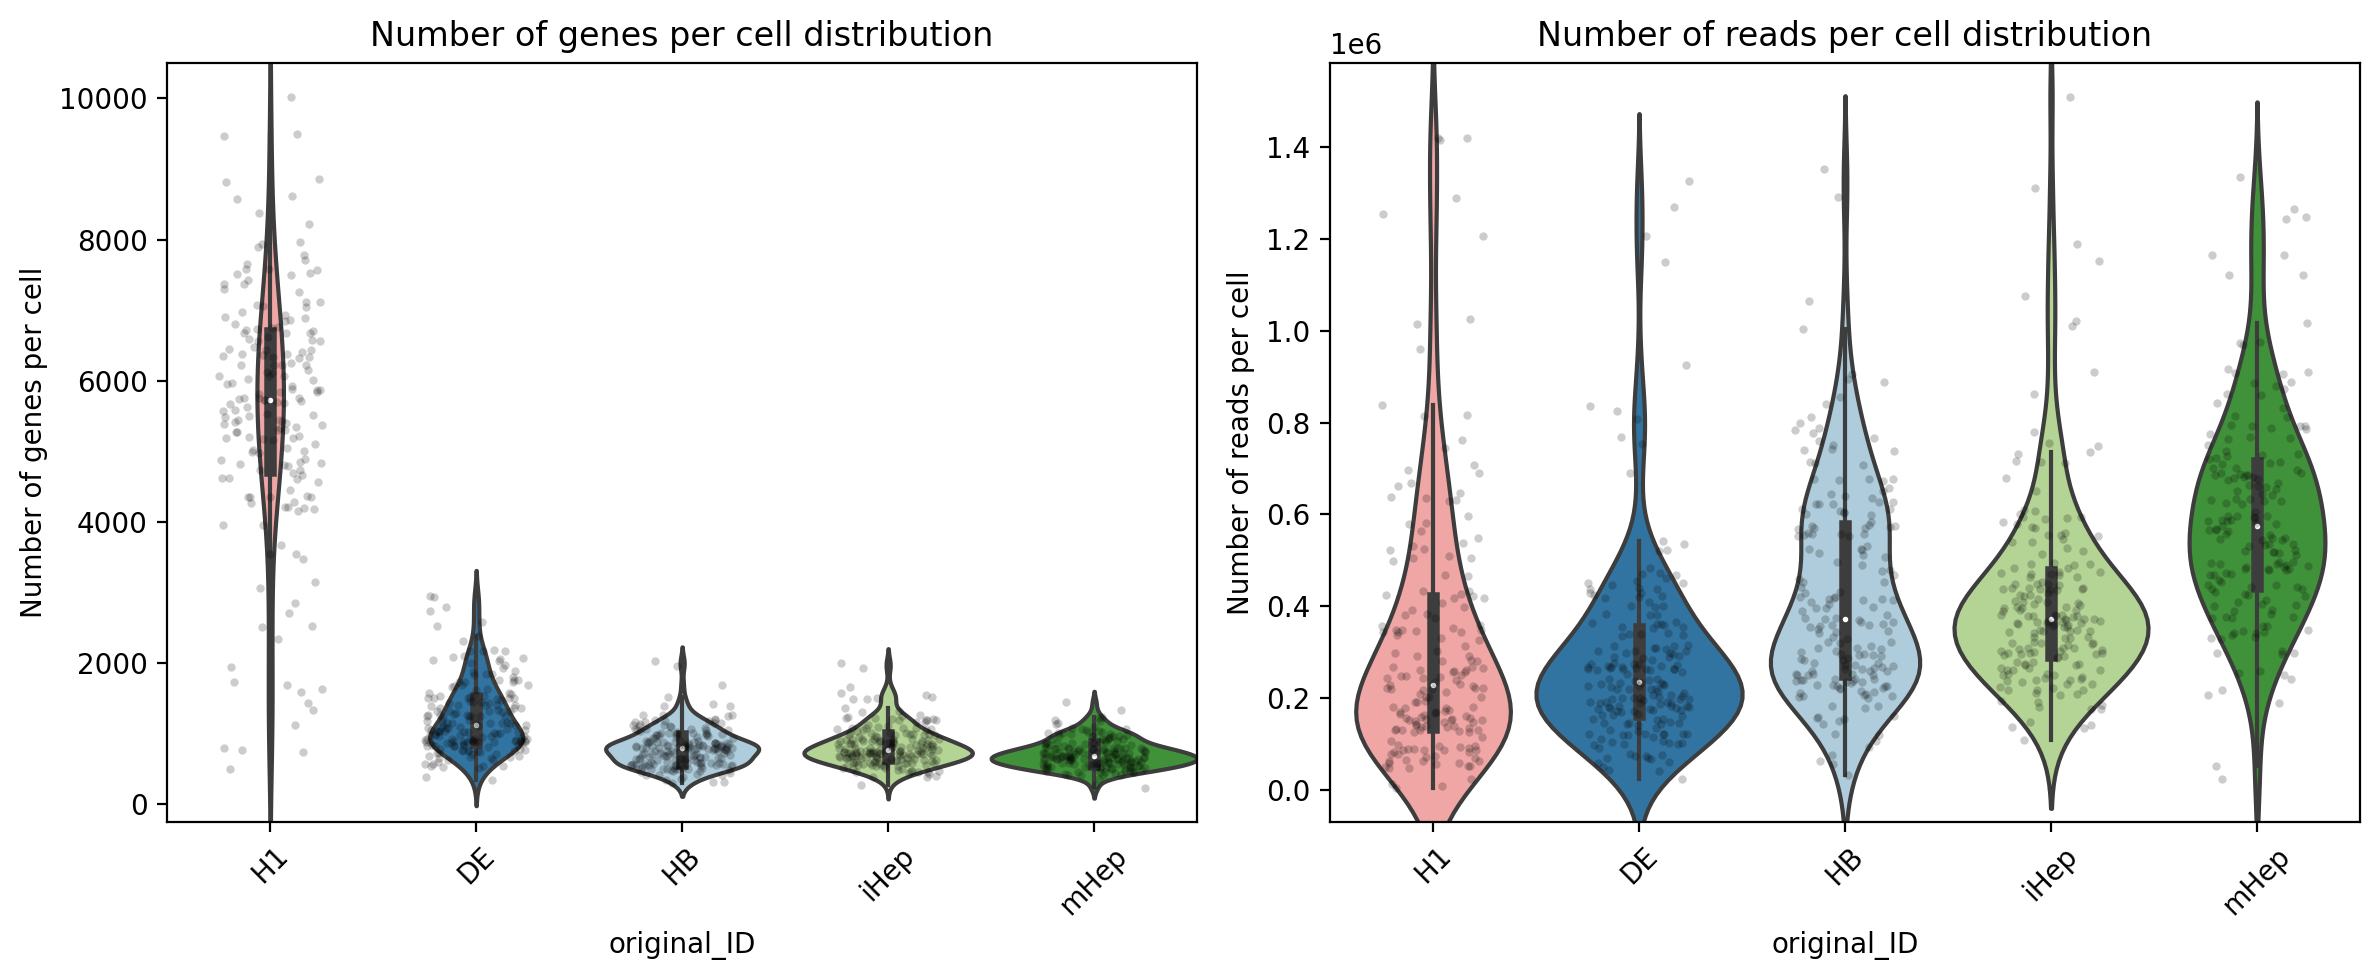

In [6]:
# plot number of genes and number of reads per cell in violin plot
data = fivestages_readsVSgene

plt.figure(figsize=(12, 5), dpi=200)

# -------------------------
# nFeature_RNA
# -------------------------
plt.subplot(1, 2, 1)

sns.violinplot(
    x="original_ID",
    y="nFeature_RNA",
    data=data,
    order=stage_order,
    palette=custom_palette,
    width=1
)

sns.stripplot(
    x="original_ID",
    y="nFeature_RNA",
    data=data,
    order=stage_order,
    color="black",
    size=3,
    alpha=0.2,
    jitter=0.25
)

plt.xticks(rotation=45)
plt.ylabel('Number of genes per cell')
plt.title("Number of genes per cell distribution")

# -------------------------
# nCount_RNA
# -------------------------
plt.subplot(1, 2, 2)

sns.violinplot(
    x="original_ID",
    y="nCount_RNA",
    data=data,
    order=stage_order,
    palette=custom_palette,
    width=1
)

sns.stripplot(
    x="original_ID",
    y="nCount_RNA",
    data=data,
    order=stage_order,
    color="black",
    size=3,
    alpha=0.2,
    jitter=0.25
)

plt.xticks(rotation=45)
plt.ylabel('Number of reads per cell')
plt.title("Number of reads per cell distribution")

plt.tight_layout()
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_ReadsVSgene_with_dots.pdf", 
            format="pdf", bbox_inches="tight")

plt.show()

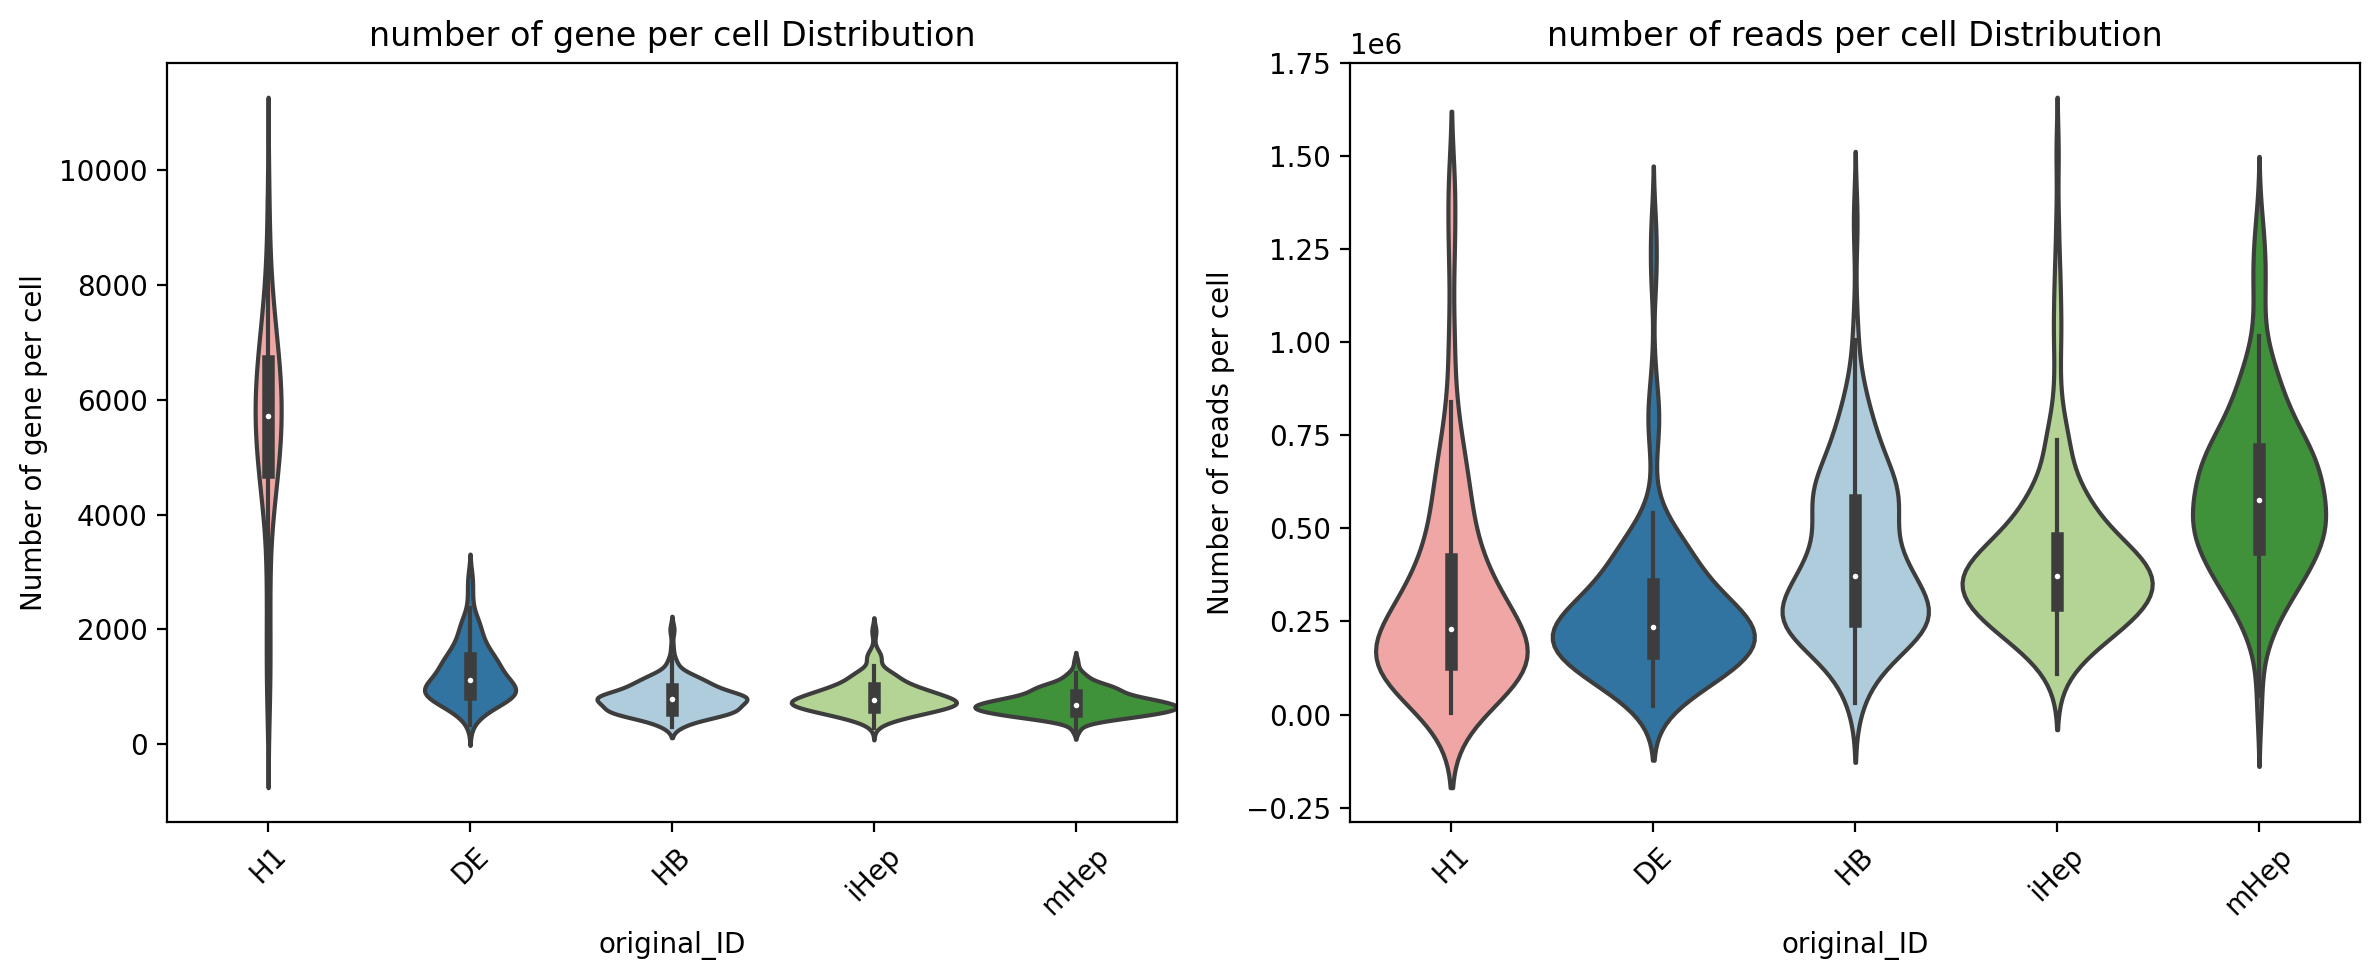

In [10]:
#plot number of genes and number of reads per cell in violin plot
data = fivestages_readsVSgene
# Set figure size and dpi
plt.figure(figsize=(12, 5), dpi=200)

# Violin plot for nFeature_RNA
plt.subplot(1, 2, 1)
sns.violinplot(x="original_ID", y="nFeature_RNA", data=data, order=stage_order, palette=custom_palette, 
               width=1)
plt.xticks(rotation=45)
plt.ylabel('Number of gene per cell')
plt.title("number of gene per cell Distribution")

# Violin plot for nCount_RNA
plt.subplot(1, 2, 2)
sns.violinplot(x="original_ID", y="nCount_RNA", data=data, order=stage_order, palette=custom_palette,
              width=1)
plt.xticks(rotation=45)
plt.ylabel('Number of reads per cell')
plt.title("number of reads per cell Distribution")

plt.tight_layout()
#plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_ReadsVSgene.pdf", 
#            format="pdf", bbox_inches="tight")
plt.show()

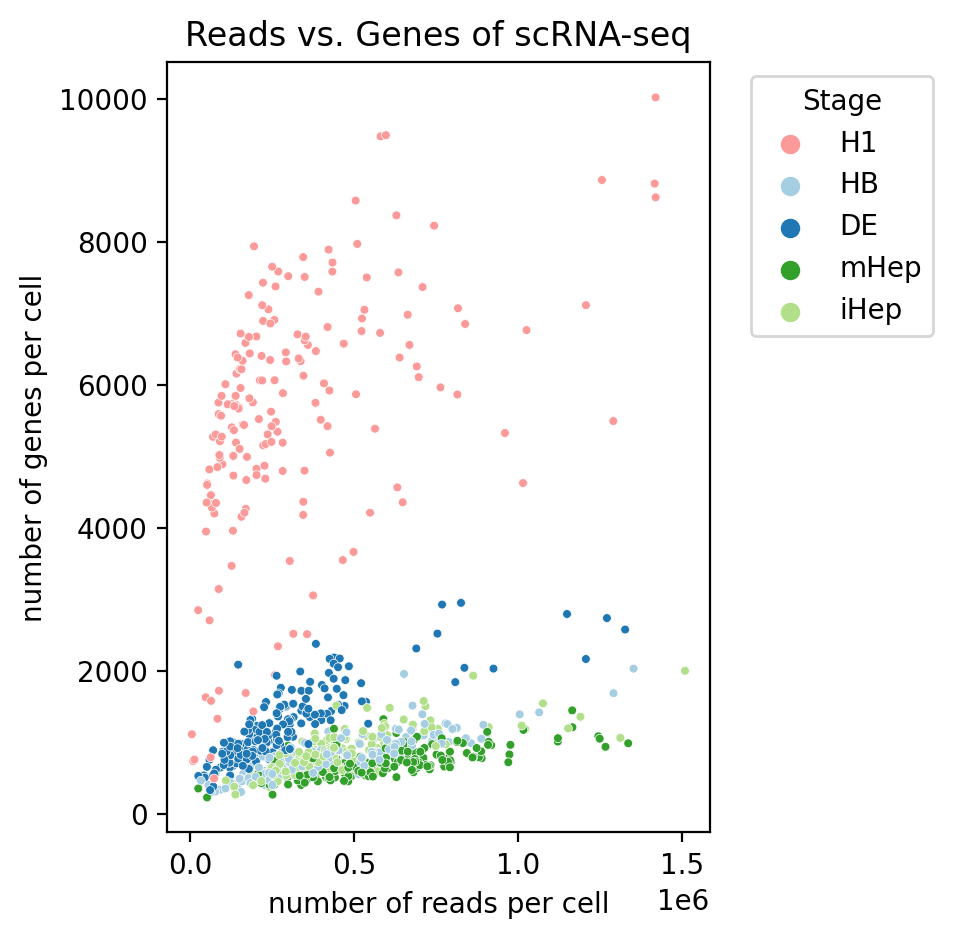

In [ ]:
#plot number of genes and number of reads per cell in scatter plot
data = fivestages_readsVSgene
# Set figure size and dpi
plt.figure(figsize=(3.5, 5), dpi=200)
# Scatter plot (dot plot) for nCount_RNA vs. nFeature_RNA
sns.scatterplot(
    x="nCount_RNA", 
    y="nFeature_RNA", 
    hue="original_ID", 
    palette=custom_palette, 
    data=data,
    s=10
)

# Set plot title and labels
plt.title("Reads vs. Genes of scRNA-seq")
plt.xlabel("number of reads per cell")
plt.ylabel("number of genes per cell")

# Show legend
plt.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc='upper left')

#plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_ReadsVSgene_dotplot.pdf", 
#            format="pdf", bbox_inches="tight")
plt.show()

# Umap

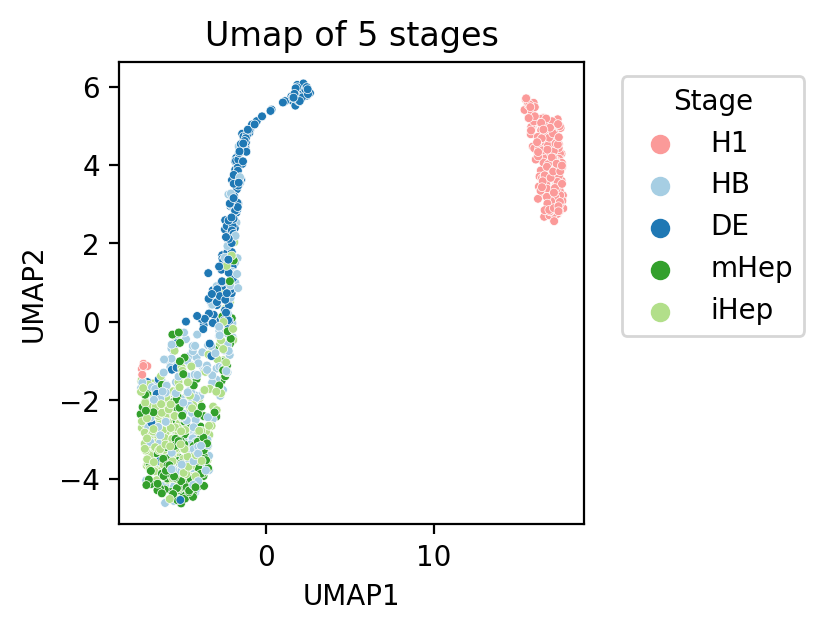

In [ ]:
#plot UMAP of five stages colorer by stages in scatter plot
data = fivestages_Umap_featuregene
# Set figure size and dpi
plt.figure(figsize=(3, 3), dpi=200)
# Scatter plot (dot plot) for nCount_RNA vs. nFeature_RNA
sns.scatterplot(
    x="UMAP_1", 
    y="UMAP_2", 
    hue="originalID", 
    palette=custom_palette, 
    data=data,
    s=10
)

# Set plot title and labels
plt.title("Umap of 5 stages")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# Show legend
plt.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc='upper left')

#plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umap_stages.pdf", 
#            format="pdf", bbox_inches="tight")
plt.show()

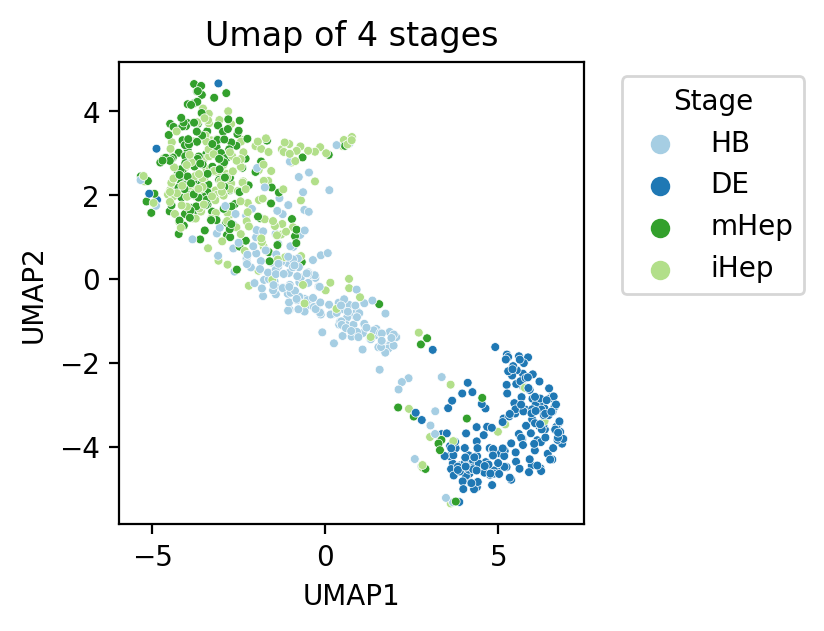

In [55]:
#plot UMAP of four stages colorer by stages in scatter plot
data = fourstages_Umap_featuregene
# Set figure size and dpi
plt.figure(figsize=(3, 3), dpi=200)
# Scatter plot (dot plot) for nCount_RNA vs. nFeature_RNA
sns.scatterplot(
    x="UMAP_1", 
    y="UMAP_2", 
    hue="originalID", 
    palette=custom_palette, 
    data=data,
    s=10
)

# Set plot title and labels
plt.title("Umap of 4 stages")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# Show legend
plt.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umap_4stages.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

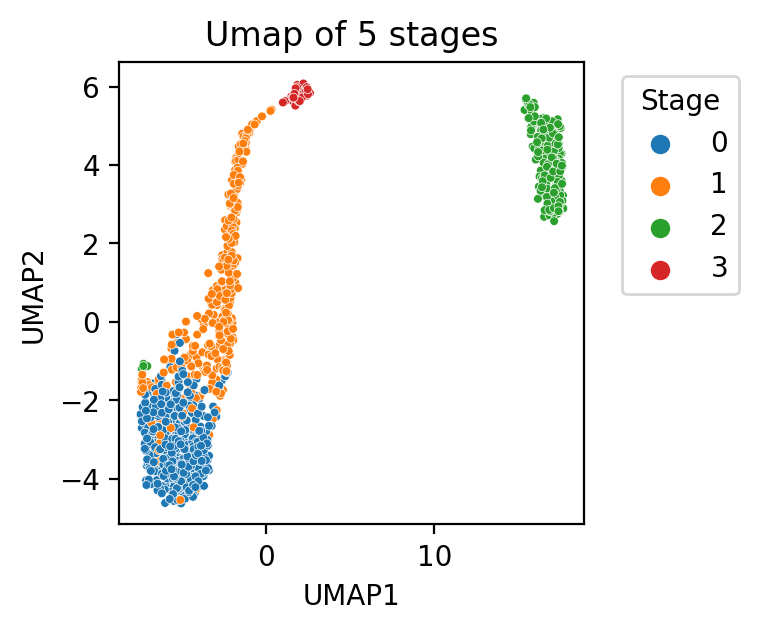

In [58]:
#plot UMAP of five stages colorer by clusters in scatter plot
data = fivestages_Umap_featuregene
# Set figure size and dpi
plt.figure(figsize=(3, 3), dpi=200)
# Scatter plot (dot plot) for nCount_RNA vs. nFeature_RNA
sns.scatterplot(
    x="UMAP_1", 
    y="UMAP_2", 
    hue="clusters", 
    palette="tab10", 
    data=data,
    s=10
)

# Set plot title and labels
plt.title("Umap of 5 stages")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# Show legend
plt.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umap_stages_clusters.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

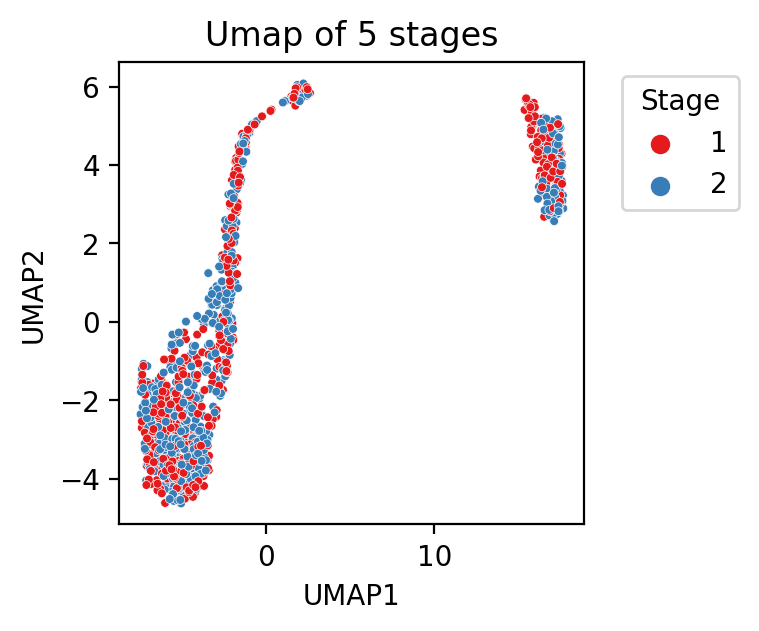

In [53]:
#plot UMAP of five stages colorer by batch in scatter plot
data = fivestages_Umap_featuregene
# Set figure size and dpi
plt.figure(figsize=(3, 3), dpi=200)
# Scatter plot (dot plot) for nCount_RNA vs. nFeature_RNA
sns.scatterplot(
    x="UMAP_1", 
    y="UMAP_2", 
    hue="originalbatch", 
    palette="Set1", 
    data=data,
    s=10
)

# Set plot title and labels
plt.title("Umap of 5 stages")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# Show legend
plt.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umap_stages_batch.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

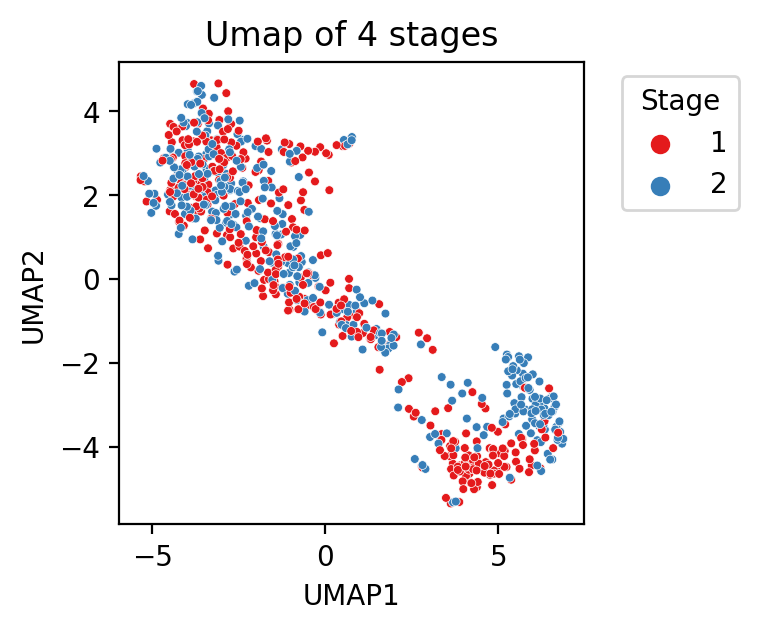

In [57]:
#plot UMAP of four stages colorer by batch in scatter plot
data = fourstages_Umap_featuregene
# Set figure size and dpi
plt.figure(figsize=(3, 3), dpi=200)
# Scatter plot (dot plot) for nCount_RNA vs. nFeature_RNA
sns.scatterplot(
    x="UMAP_1", 
    y="UMAP_2", 
    hue="originalbatch", 
    palette='Set1', 
    data=data,
    s=10
)

# Set plot title and labels
plt.title("Umap of 4 stages")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# Show legend
plt.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umap_4stages_batch.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

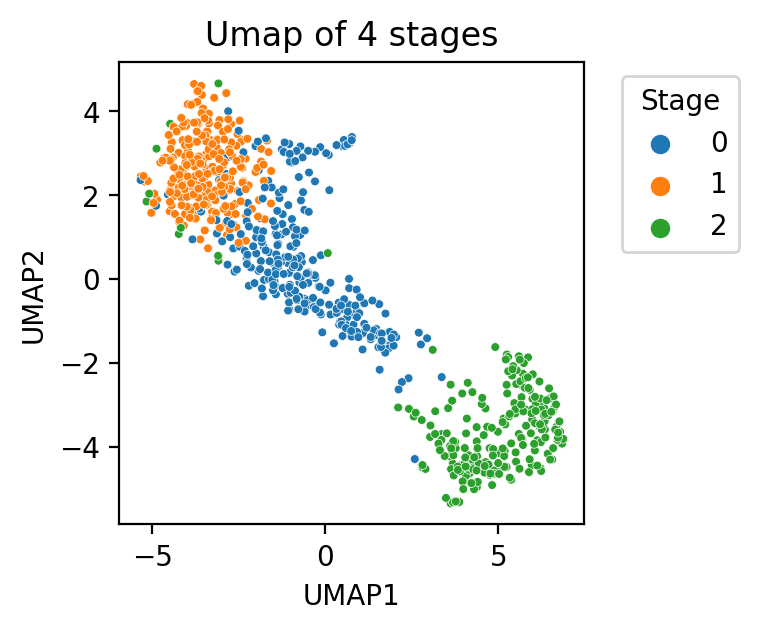

In [60]:
#plot UMAP of four stages colorer by clusters in scatter plot
data = fourstages_Umap_featuregene
# Set figure size and dpi
plt.figure(figsize=(3, 3), dpi=200)
# Scatter plot (dot plot) for nCount_RNA vs. nFeature_RNA
sns.scatterplot(
    x="UMAP_1", 
    y="UMAP_2", 
    hue="clusters", 
    palette='tab10', 
    data=data,
    s=10
)

# Set plot title and labels
plt.title("Umap of 4 stages")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# Show legend
plt.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umap_4stages_cluster.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

# PCA

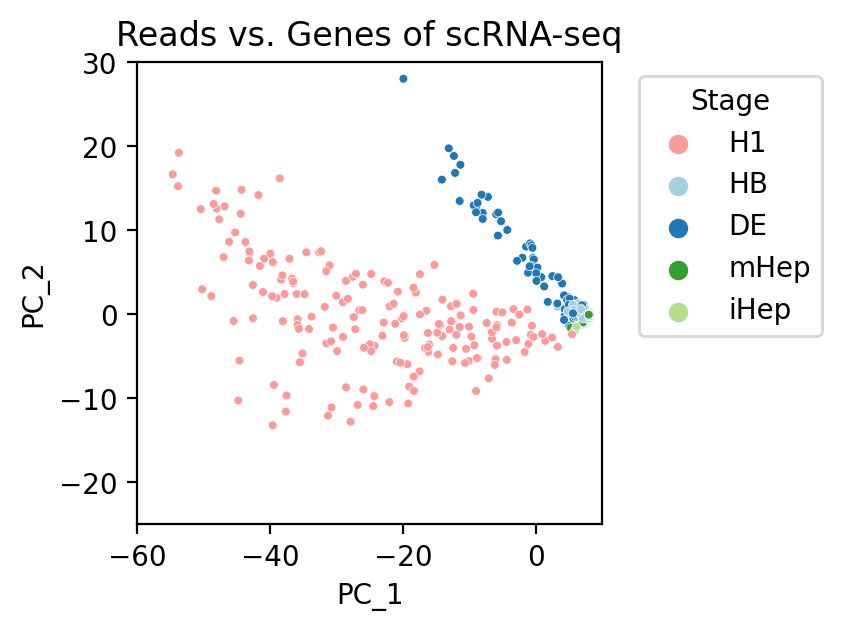

In [23]:
#plot PCA colored by stages in scatter plot
data = fivestages_pca
# Set figure size and dpi
plt.figure(figsize=(3, 3), dpi=200)
# Scatter plot (dot plot) for nCount_RNA vs. nFeature_RNA
sns.scatterplot(
    x="PC_1", 
    y="PC_2", 
    hue="originalID", 
    palette=custom_palette, 
    data=data,
    s=10
)

# Set plot title and labels
plt.title("Reads vs. Genes of scRNA-seq")
plt.xlabel("PC_1")
plt.ylabel("PC_2")
plt.xlim(-60, 10)   # set x-axis range
plt.ylim(-25, 30)   # set y-axis range



# Show legend
plt.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_PCA_genecounts.pdf", 
            format="pdf", bbox_inches="tight")
plt.show()

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


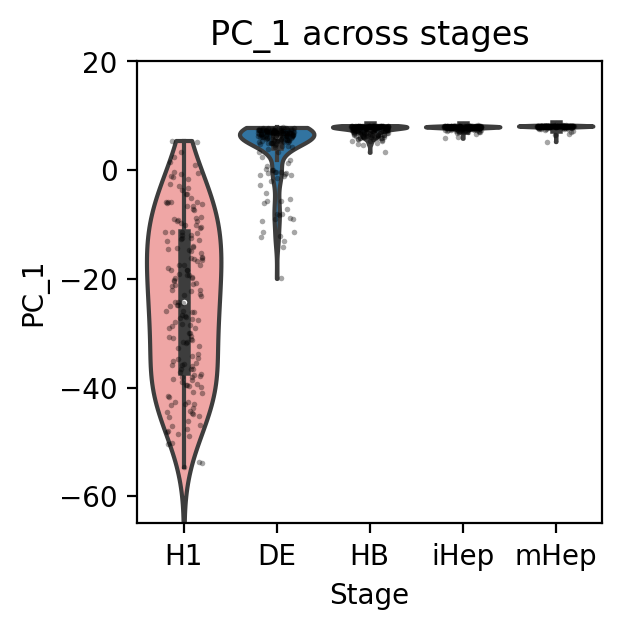

In [9]:
# PC1 violin plots with dots
data = fivestages_pca.copy()
stage_order = ["H1", "DE", "HB", "iHep", "mHep"]

plt.figure(figsize=(3, 3), dpi=200)

sns.violinplot(
    x="originalID",
    y="PC_1",
    data=data,
    order=stage_order,
    palette=custom_palette,
    inner="box",
    cut=0,
    scale="width"
)

sns.stripplot(
    x="originalID",
    y="PC_1",
    data=data,
    order=stage_order,
    color="black",
    size=2,
    alpha=0.35,
    jitter=0.2
)

plt.title("PC_1 across stages")
plt.xlabel("Stage")
plt.ylabel("PC_1")
plt.ylim(-65, 20)

plt.savefig(
    "/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_PC1_violin_by_stage_with_dots.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()

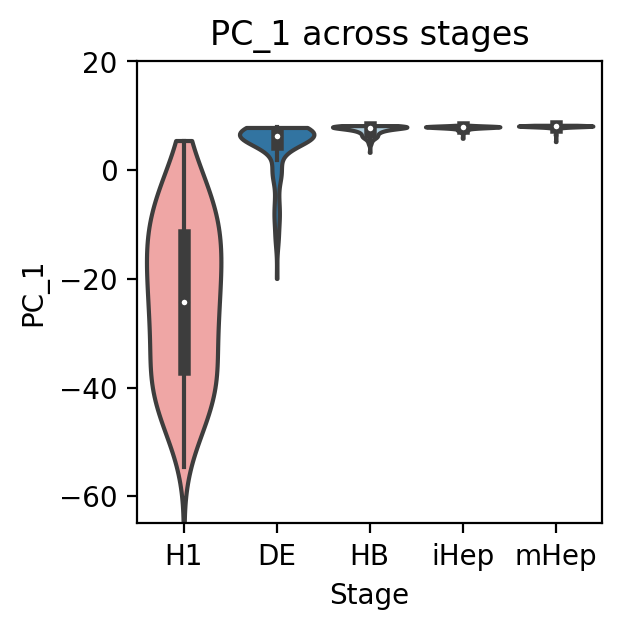

In [4]:
#PC1 violin plots
data = fivestages_pca.copy()
stage_order = ["H1", "DE", "HB", "iHep", "mHep"]

plt.figure(figsize=(3, 3), dpi=200)

sns.violinplot(
    x="originalID",
    y="PC_1",
    data=data,
    order=stage_order,
    palette=custom_palette,
    inner="box",
    cut=0,
    scale="width"   # all violins get same width
)

plt.title("PC_1 across stages")
plt.xlabel("Stage")
plt.ylabel("PC_1")
plt.ylim(-65, 20)

plt.savefig(
    "/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_PC1_violin_by_stage.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()

/tmp/ipykernel_1612639/2654588337.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap1 = cm.get_cmap("Purples")  # For Genecount
/tmp/ipykernel_1612639/2654588337.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap2 = cm.get_cmap("Reds")     # For Readscount


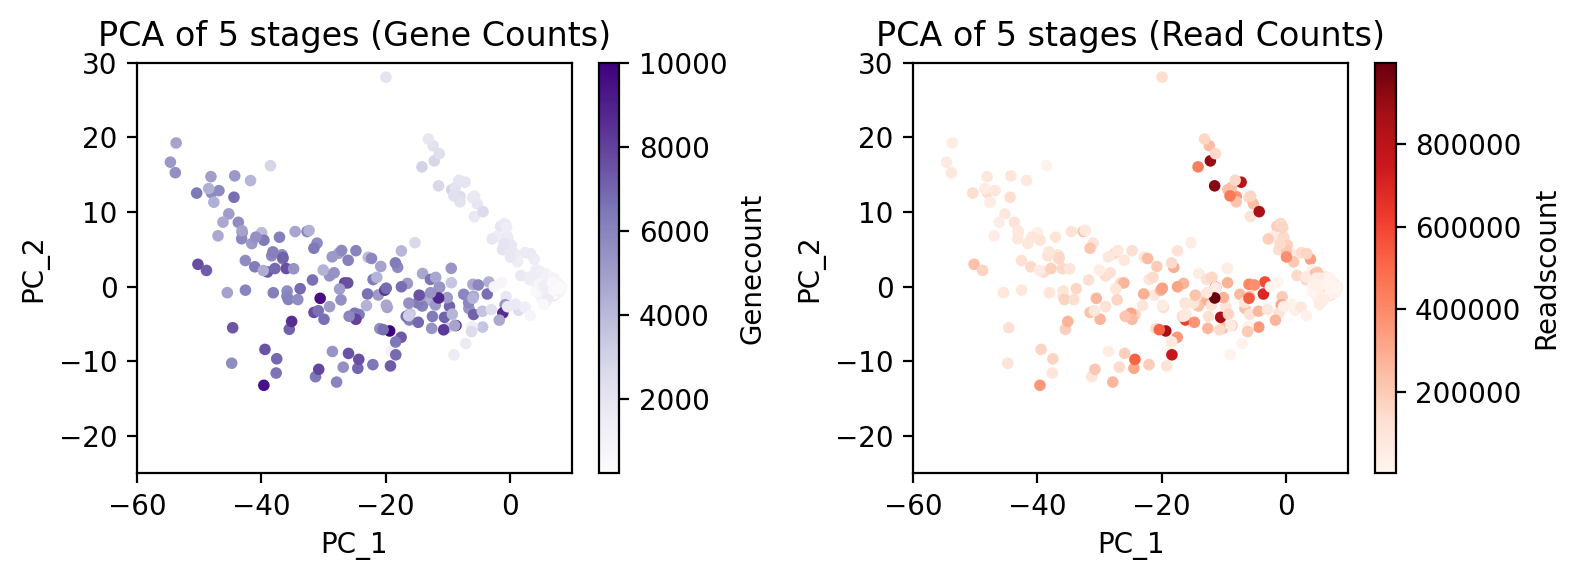

In [ ]:
#plot PCA colored by genecounts in scatter plot
# Define colormaps
cmap1 = cm.get_cmap("Purples")  # For Genecount
cmap2 = cm.get_cmap("Reds")     # For Readscount

# Normalize values for color mapping
norm1 = mcolors.Normalize(vmin=data["Genecount"].min(), vmax=data["Genecount"].max())
norm2 = mcolors.Normalize(vmin=data["Readscount"].min(), vmax=data["Readscount"].max())

# Set figure size and dpi
fig, axes = plt.subplots(1, 2, figsize=(8, 3), dpi=200)

# Scatter plot for Genecount
scatter1 = axes[0].scatter(
    data["PC_1"], data["PC_2"], 
    c=data["Genecount"], cmap=cmap1, 
    s=10  # Smaller dots
)
axes[0].set_title("PCA of 5 stages (Gene Counts)")
axes[0].set_xlabel("PC_1")
axes[0].set_ylabel("PC_2")
axes[0].set_xlim(-60, 10)
axes[0].set_ylim(-25, 30)
cbar1 = fig.colorbar(scatter1, ax=axes[0])
cbar1.set_label("Genecount")

# Scatter plot for Readscount
scatter2 = axes[1].scatter(
    data["PC_1"], data["PC_2"], 
    c=data["Readscount"], cmap=cmap2, 
    s=10  # Smaller dots
)
axes[1].set_title("PCA of 5 stages (Read Counts)")
axes[1].set_xlabel("PC_1")
axes[1].set_ylabel("PC_2")
axes[1].set_xlim(-60, 10)
axes[1].set_ylim(-25, 30)
cbar2 = fig.colorbar(scatter2, ax=axes[1])
cbar2.set_label("Readscount")

# Adjust layout and save the plot
plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_PCA_gene_readscounts.pdf", 
            format="pdf", bbox_inches="tight")

# Display plot
plt.show()

# feature genes 

In [79]:
fivestages_Umap_featuregene.columns

Index(['UMAP_1', 'UMAP_2', 'clusters', 'originalbatch', 'originalID', 'SOX17',
       'FOXA2', 'ALB', 'HNF4A', 'AFP', 'LEFTY1', 'FGA', 'FGG', 'FGB', 'APOA1',
       'APOA2', 'APOA4', 'APOA5', 'APOC3', 'NANOG', 'SOX2', 'ZFP42', 'KLF4',
       'ESRRB', 'NR5A2', 'SOX17.1', 'FOXA2.1', 'ALB.1', 'HNF4A.1', 'AFP.1',
       'LEFTY1.1', 'FGA.1', 'FGG.1', 'FGB.1', 'APOA1.1', 'APOA2.1', 'APOA4.1',
       'APOA5.1', 'APOC3.1'],
      dtype='object')

In [5]:
fivestages_Umap_featuregene

,UMAP_1,UMAP_2,clusters,originalbatch,originalID,SOX17,FOXA2,ALB,HNF4A,AFP,...,AFP.1,LEFTY1.1,FGA.1,FGG.1,FGB.1,APOA1.1,APOA2.1,APOA4.1,APOA5.1,APOC3.1
H1-scRNAfresh-plate1-30,17.579255,3.113338,2,1,H1,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000
HB-scRNAfresh-plate1-70,-5.860179,-0.972740,1,1,HB,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.019962,0.114202,0.0,0.000000
DE-scRNAfresh-plate1-28,-1.989144,3.019694,1,1,DE,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000
mHep-scRNAfresh-plate1-36,-2.931173,-2.412416,0,1,mHep,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000
iHep-scRNAfresh-plate2-39,-6.070575,-3.906086,0,2,iHep,0.024962,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.119008,0.000000,0.000000,0.0,0.024962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
iHep-scRNAfresh-plate2-66,-2.930070,-1.777725,1,2,iHep,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000
iHep-scRNAfresh-plate2-55,-5.047148,-3.119417,0,2,iHep,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000
iHep-scRNAfresh-plate2-56,-5.017547,-2.788229,0,2,iHep,0.000000,0.0,0.0,0.045211,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000
iHep-scRNAfresh-plate2-72,-3.800676,-3.543087,0,2,iHep,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000


/tmp/ipykernel_1911423/1961372592.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("Reds")


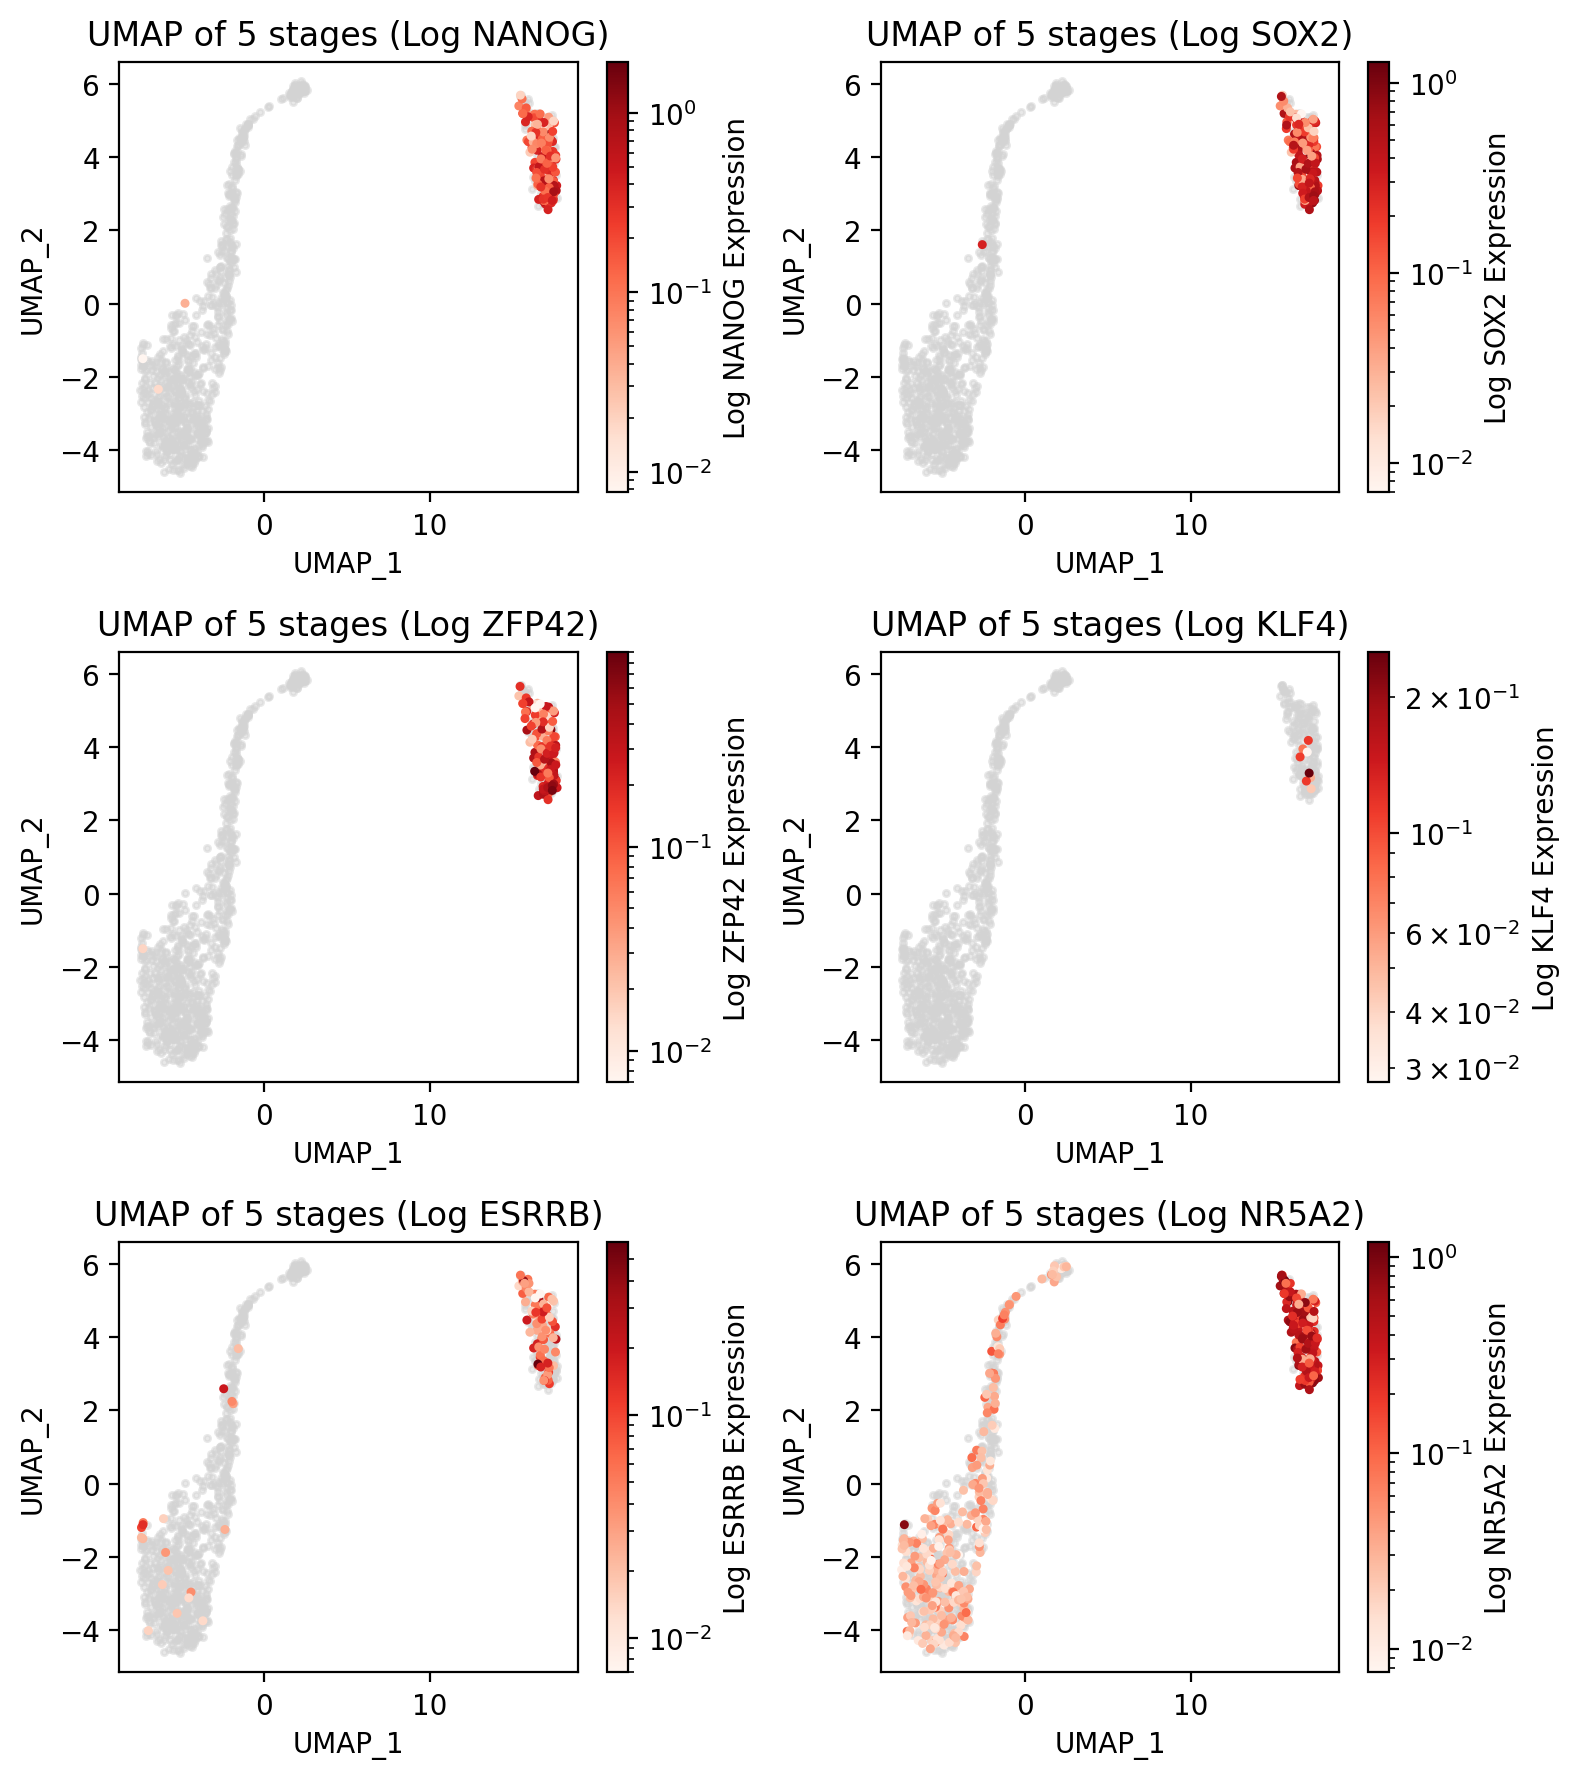

In [44]:
# H1 marker genes
from matplotlib.colors import LogNorm
from matplotlib.colors import PowerNorm
# Data
data = fivestages_Umap_featuregene
ES_markergene = ['NANOG', 'SOX2', 'ZFP42', 'KLF4', 'ESRRB', 'NR5A2']

# Apply log transformation to gene expression values
data_logged = data.copy()
for gene in ES_markergene:
    data_logged[gene] = np.log1p(data[gene])  # log1p to avoid log(0) issues

# Define subplot grid
n_rows = len(ES_markergene) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(8, n_rows * 3), dpi=200)

# Flatten axes array in case of 2D grid
axes = axes.flatten()

# Loop over genes and plot log-transformed values
for i, gene in enumerate(ES_markergene):
    ax = axes[i]
    
    # Log transformation for color scaling
    log_expression = np.log1p(data[gene])

    # Define blue gradient colormap
    cmap = cm.get_cmap("Reds")  

    # Normalize color scaling (log scale)
    norm = mcolors.LogNorm(vmin=log_expression[log_expression > 0].min(), vmax=log_expression.max())

    # Plot zero-expression points in grey
    ax.scatter(data["UMAP_1"][log_expression == 0], 
               data["UMAP_2"][log_expression == 0], 
               color="lightgrey", s=5, alpha=0.5)

    # Plot nonzero expression points with gradient
    scatter = ax.scatter(
        data["UMAP_1"][log_expression > 0], 
        data["UMAP_2"][log_expression > 0], 
        c=log_expression[log_expression > 0], cmap=cmap, norm=norm,
        s=5  # Small dot size
    )

    # Set subplot title and labels
    axes[i].set_title(f"UMAP of 5 stages (Log {gene})")
    axes[i].set_xlabel("UMAP_1")
    axes[i].set_ylabel("UMAP_2")

    # Add colorbar
    cbar = fig.colorbar(scatter, ax=axes[i])
    cbar.set_label(f"Log {gene} Expression")

# Adjust layout and save the plot
plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umaps_H1makergenes.pdf", format="pdf", bbox_inches="tight")

# Display plot
plt.show()

/tmp/ipykernel_1917021/3984462459.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("Blues")


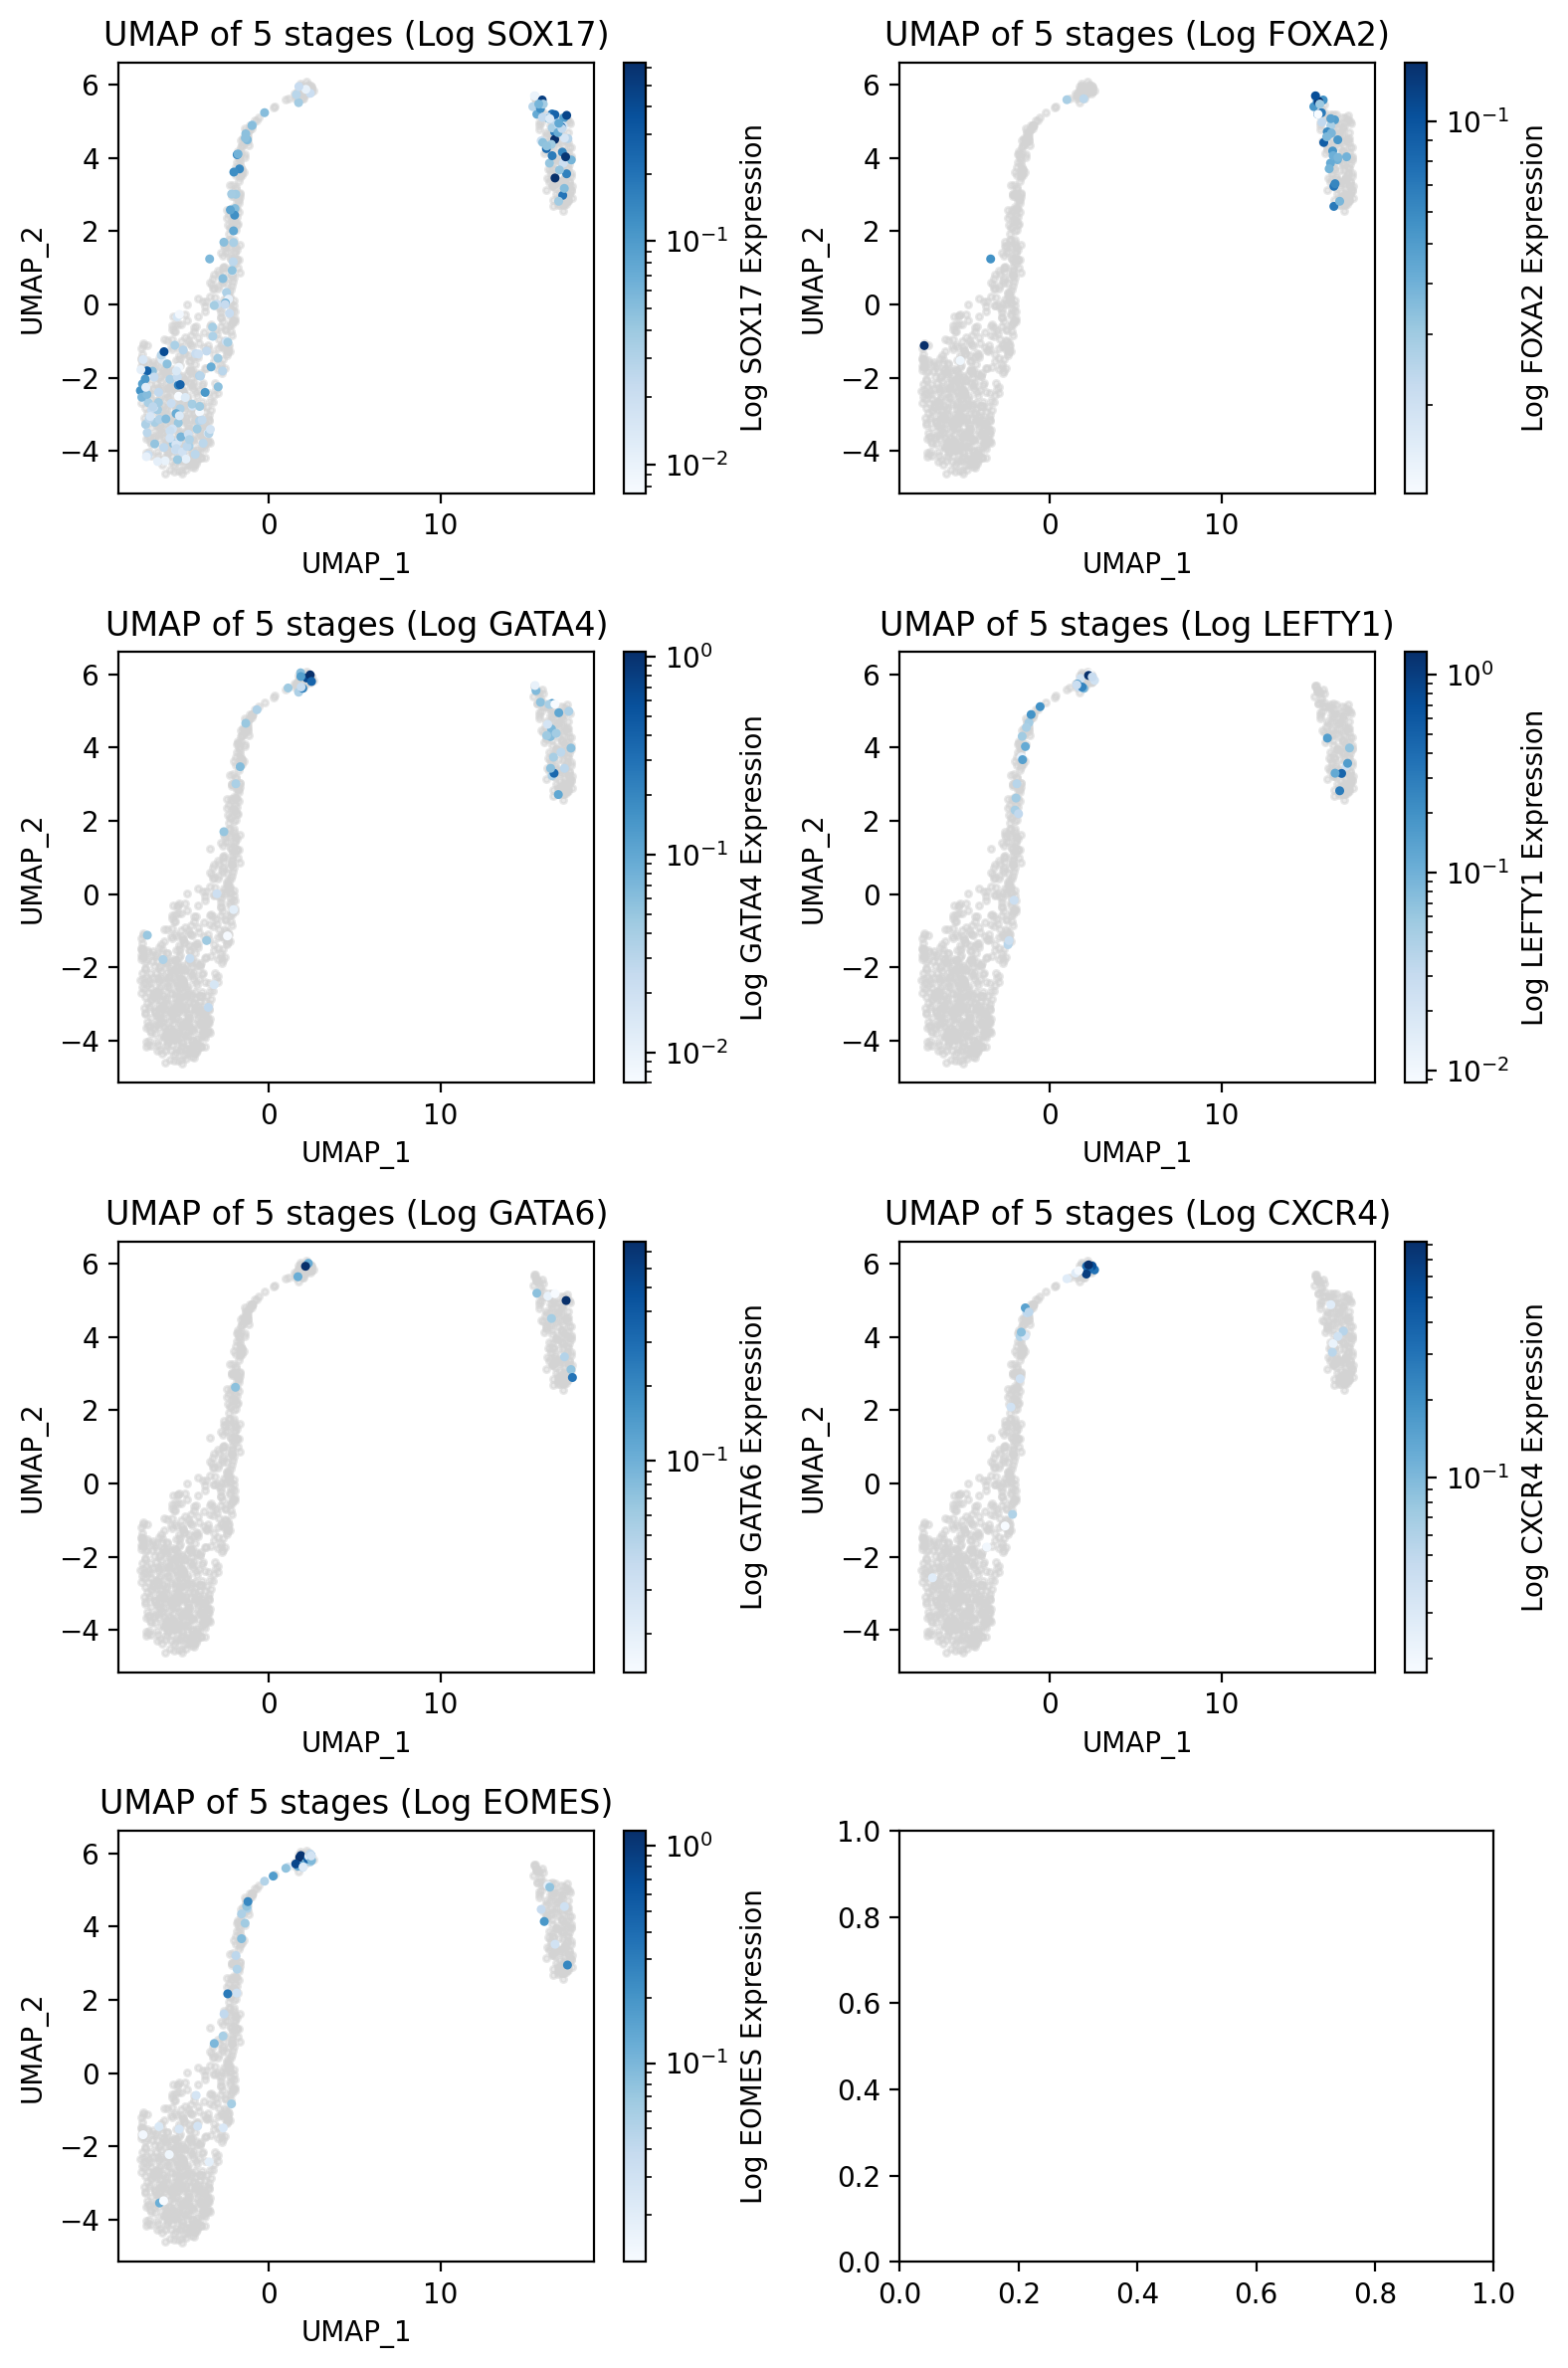

In [6]:
# DE marker genes 
data = fivestages_Umap_featuregene
DE_markergene = ['SOX17', 'FOXA2', 'GATA4', 'LEFTY1', 'GATA6', 'CXCR4','EOMES']

# Apply log transformation to gene expression values
data_logged = data.copy()
for gene in DE_markergene:
    data_logged[gene] = np.log1p(data[gene])  # log1p to avoid log(0) issues

# Define subplot grid
n_rows = len(DE_markergene) // 2 +1
fig, axes = plt.subplots(n_rows, 2, figsize=(8, n_rows * 3), dpi=200)

# Flatten axes array in case of 2D grid
axes = axes.flatten()

# Loop over genes and plot log-transformed values
for i, gene in enumerate(DE_markergene):
    ax = axes[i]
    
    # Log transformation for color scaling
    log_expression = np.log1p(data[gene])

    # Define blue gradient colormap
    cmap = cm.get_cmap("Blues")  

    # Normalize color scaling (log scale)
    norm = mcolors.LogNorm(vmin=log_expression[log_expression > 0].min(), vmax=log_expression.max())

    # Plot zero-expression points in grey
    ax.scatter(data["UMAP_1"][log_expression == 0], 
               data["UMAP_2"][log_expression == 0], 
               color="lightgrey", s=5, alpha=0.5)

    # Plot nonzero expression points with gradient
    scatter = ax.scatter(
        data["UMAP_1"][log_expression > 0], 
        data["UMAP_2"][log_expression > 0], 
        c=log_expression[log_expression > 0], cmap=cmap, norm=norm,
        s=5  # Small dot size
    )

    # Set subplot title and labels
    axes[i].set_title(f"UMAP of 5 stages (Log {gene})")
    axes[i].set_xlabel("UMAP_1")
    axes[i].set_ylabel("UMAP_2")

    # Add colorbar
    cbar = fig.colorbar(scatter, ax=axes[i])
    cbar.set_label(f"Log {gene} Expression")

# Adjust layout and save the plot
plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umaps_DEmakergenes.pdf", format="pdf", bbox_inches="tight")

# Display plot
plt.show()

/tmp/ipykernel_1917021/632727500.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("Blues")


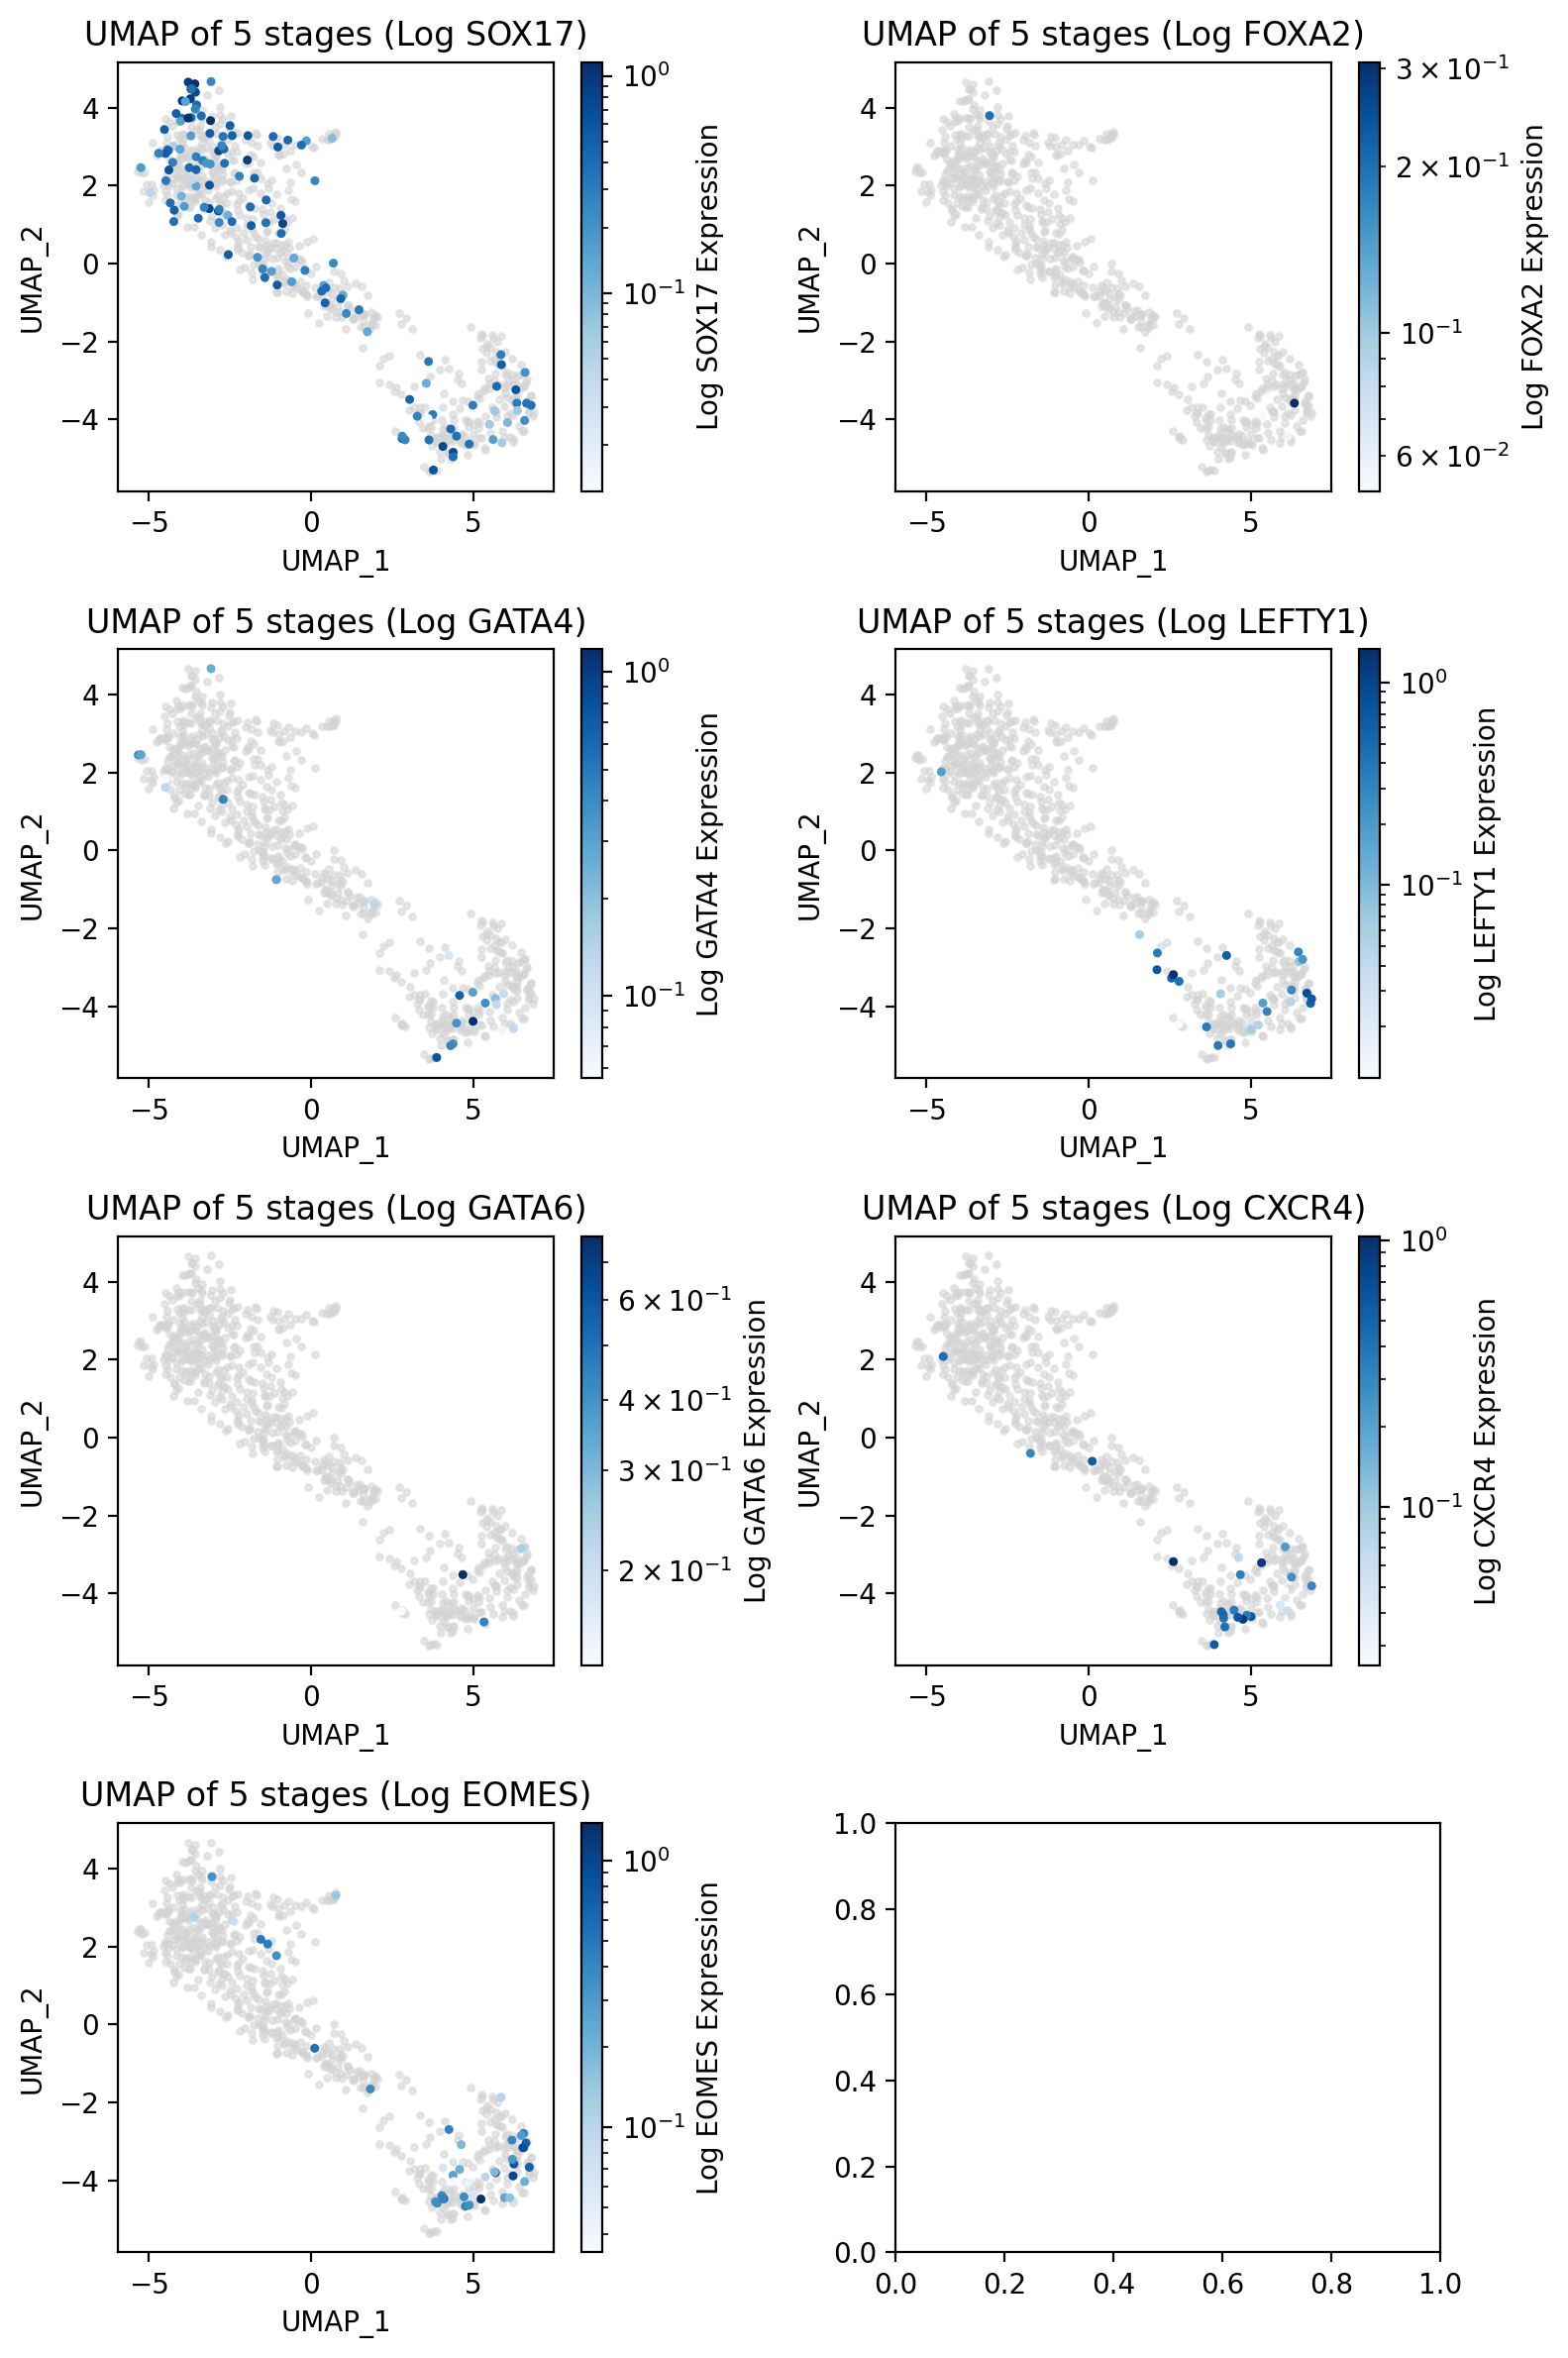

In [16]:
# DE marker genes 
data = fourstages_Umap_featuregene
DE_markergene = ['SOX17', 'FOXA2', 'GATA4', 'LEFTY1', 'GATA6', 'CXCR4','EOMES']

# Apply log transformation to gene expression values
data_logged = data.copy()
for gene in DE_markergene:
    data_logged[gene] = np.log1p(data[gene])  # log1p to avoid log(0) issues

# Define subplot grid
n_rows = len(DE_markergene) // 2 +1
fig, axes = plt.subplots(n_rows, 2, figsize=(8, n_rows * 3), dpi=200)

# Flatten axes array in case of 2D grid
axes = axes.flatten()

# Loop over genes and plot log-transformed values
for i, gene in enumerate(DE_markergene):
    ax = axes[i]
    
    # Log transformation for color scaling
    log_expression = np.log1p(data[gene])

    # Define blue gradient colormap
    cmap = cm.get_cmap("Blues")  

    # Normalize color scaling (log scale)
    norm = mcolors.LogNorm(vmin=log_expression[log_expression > 0].min(), vmax=log_expression.max())

    # Plot zero-expression points in grey
    ax.scatter(data["UMAP_1"][log_expression == 0], 
               data["UMAP_2"][log_expression == 0], 
               color="lightgrey", s=5, alpha=0.5)

    # Plot nonzero expression points with gradient
    scatter = ax.scatter(
        data["UMAP_1"][log_expression > 0], 
        data["UMAP_2"][log_expression > 0], 
        c=log_expression[log_expression > 0], cmap=cmap, norm=norm,
        s=5  # Small dot size
    )

    # Set subplot title and labels
    axes[i].set_title(f"UMAP of 5 stages (Log {gene})")
    axes[i].set_xlabel("UMAP_1")
    axes[i].set_ylabel("UMAP_2")

    # Add colorbar
    cbar = fig.colorbar(scatter, ax=axes[i])
    cbar.set_label(f"Log {gene} Expression")

# Adjust layout and save the plot
plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umaps_four_stages_DEmakergenes.pdf", format="pdf", bbox_inches="tight")

# Display plot
plt.show()

/tmp/ipykernel_1917021/815514353.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("Greens")


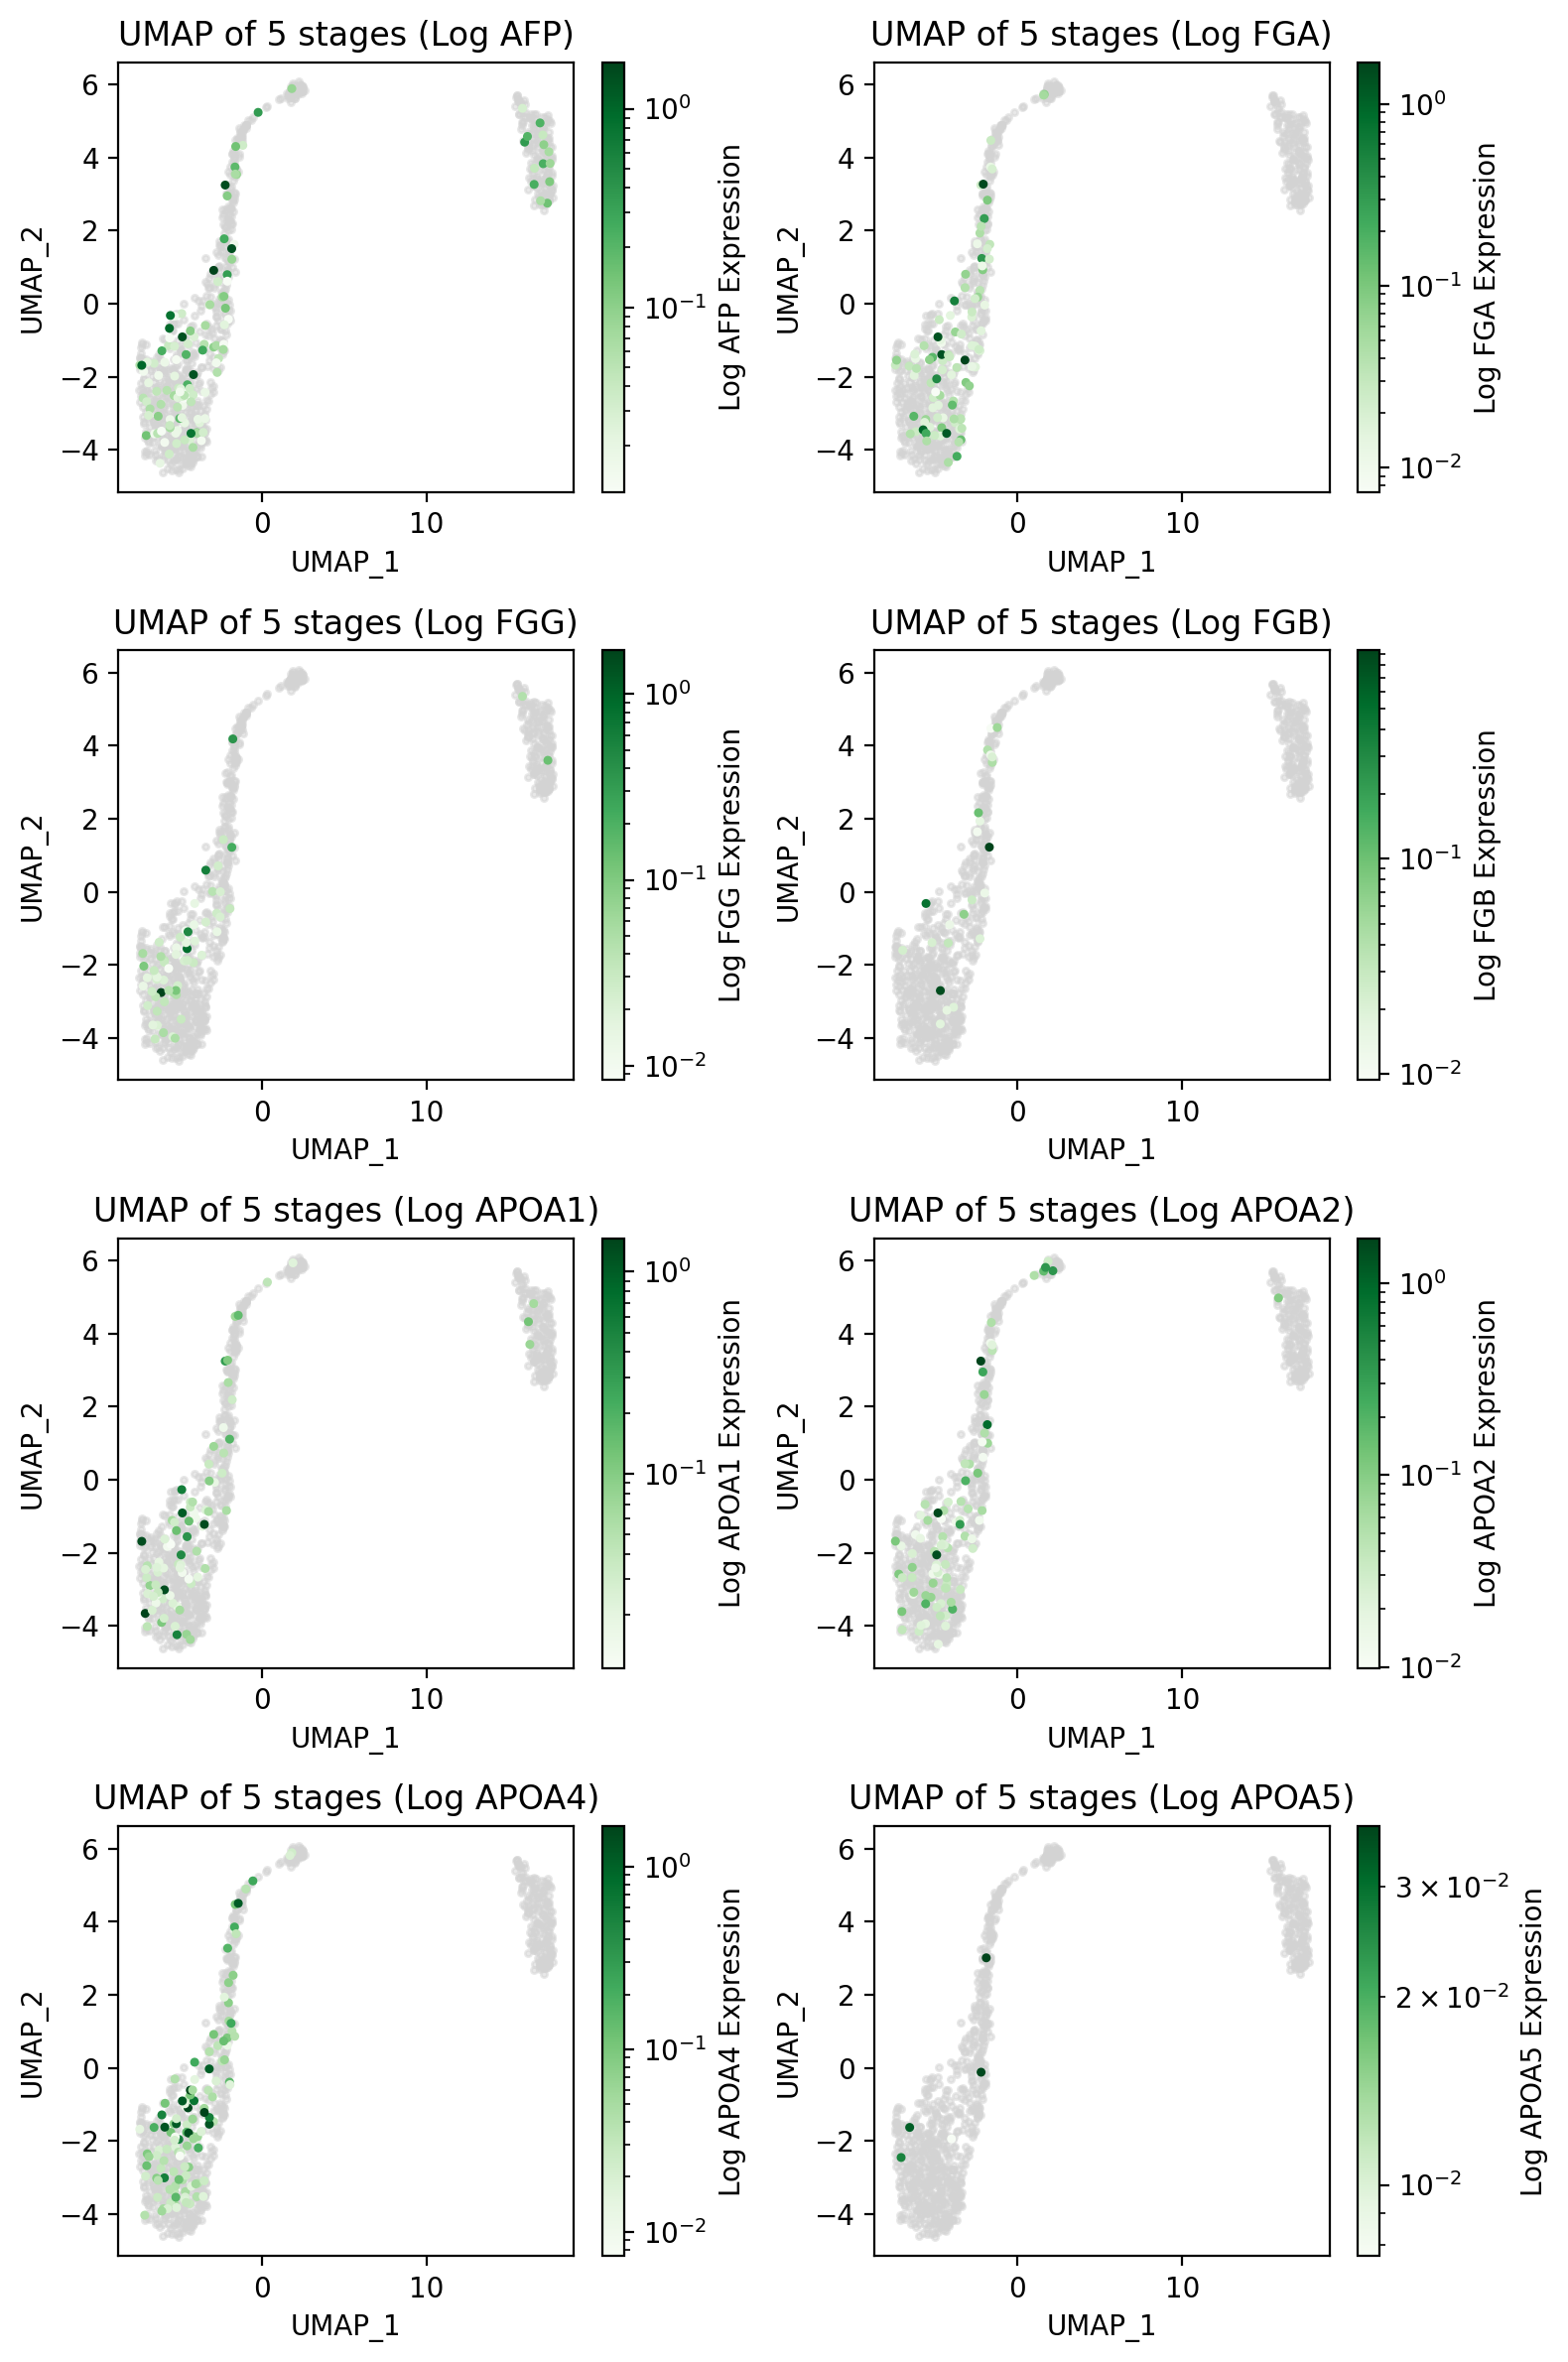

In [9]:
# HB marker genes 
data = fivestages_Umap_featuregene
HB_markergene = ['AFP', 'FGA', 'FGG', 'FGB', 'APOA1', 'APOA2','APOA4','APOA5']

# Apply log transformation to gene expression values
data_logged = data.copy()
for gene in HB_markergene:
    data_logged[gene] = np.log1p(data[gene])  # log1p to avoid log(0) issues

# Define subplot grid
n_rows = len(HB_markergene) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(8, n_rows * 3), dpi=200)

# Flatten axes array in case of 2D grid
axes = axes.flatten()

# Loop over genes and plot log-transformed values
for i, gene in enumerate(HB_markergene):
    ax = axes[i]
    
    # Log transformation for color scaling
    log_expression = np.log1p(data[gene])

    # Define blue gradient colormap
    cmap = cm.get_cmap("Greens")  

    # Normalize color scaling (log scale)
    norm = mcolors.LogNorm(vmin=log_expression[log_expression > 0].min(), vmax=log_expression.max())

    # Plot zero-expression points in grey
    ax.scatter(data["UMAP_1"][log_expression == 0], 
               data["UMAP_2"][log_expression == 0], 
               color="lightgrey", s=5, alpha=0.5)

    # Plot nonzero expression points with gradient
    scatter = ax.scatter(
        data["UMAP_1"][log_expression > 0], 
        data["UMAP_2"][log_expression > 0], 
        c=log_expression[log_expression > 0], cmap=cmap, norm=norm,
        s=5  # Small dot size
    )

    # Set subplot title and labels
    axes[i].set_title(f"UMAP of 5 stages (Log {gene})")
    axes[i].set_xlabel("UMAP_1")
    axes[i].set_ylabel("UMAP_2")

    # Add colorbar
    cbar = fig.colorbar(scatter, ax=axes[i])
    cbar.set_label(f"Log {gene} Expression")

# Adjust layout and save the plot
plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umaps_HBmakergenes.pdf", format="pdf", bbox_inches="tight")

# Display plot
plt.show()

/tmp/ipykernel_1917021/2902468785.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("Greens")


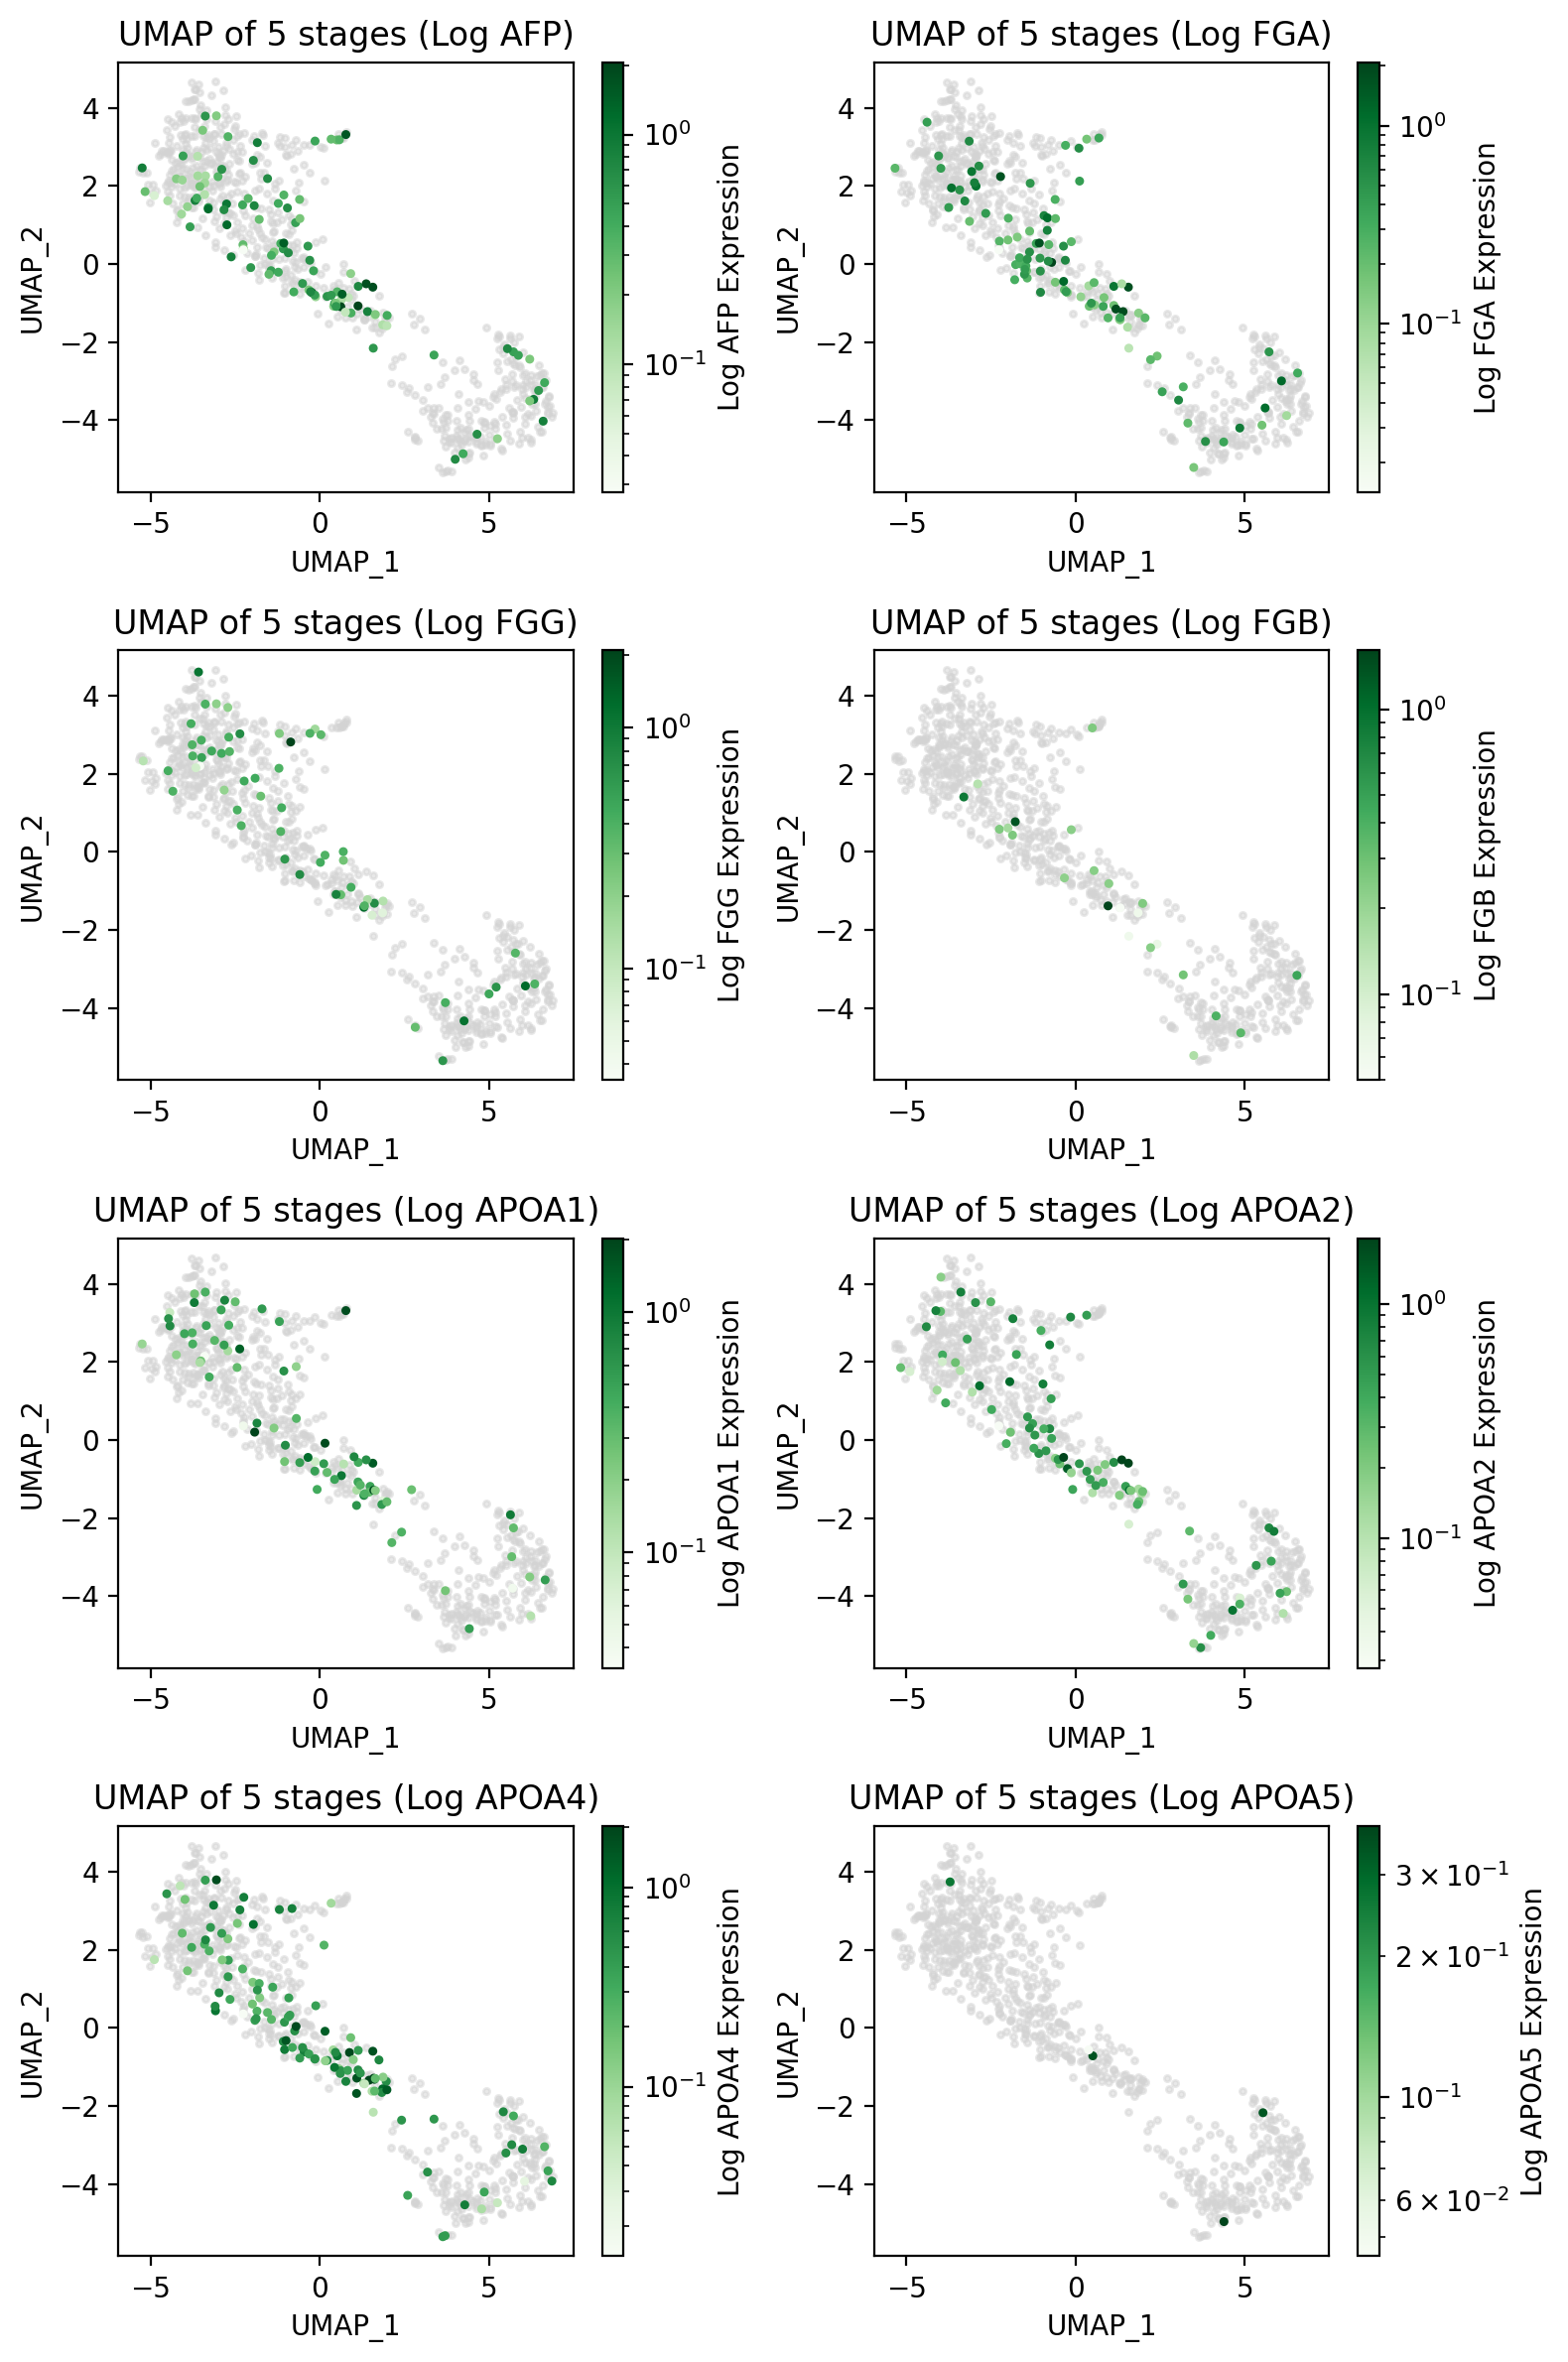

In [15]:
# HB marker genes 
data = fourstages_Umap_featuregene
HB_markergene = ['AFP', 'FGA', 'FGG', 'FGB', 'APOA1', 'APOA2','APOA4','APOA5']

# Apply log transformation to gene expression values
data_logged = data.copy()
for gene in HB_markergene:
    data_logged[gene] = np.log1p(data[gene])  # log1p to avoid log(0) issues

# Define subplot grid
n_rows = len(HB_markergene) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(8, n_rows * 3), dpi=200)

# Flatten axes array in case of 2D grid
axes = axes.flatten()

# Loop over genes and plot log-transformed values
for i, gene in enumerate(HB_markergene):
    ax = axes[i]
    
    # Log transformation for color scaling
    log_expression = np.log1p(data[gene])

    # Define blue gradient colormap
    cmap = cm.get_cmap("Greens")  

    # Normalize color scaling (log scale)
    norm = mcolors.LogNorm(vmin=log_expression[log_expression > 0].min(), vmax=log_expression.max())

    # Plot zero-expression points in grey
    ax.scatter(data["UMAP_1"][log_expression == 0], 
               data["UMAP_2"][log_expression == 0], 
               color="lightgrey", s=5, alpha=0.5)

    # Plot nonzero expression points with gradient
    scatter = ax.scatter(
        data["UMAP_1"][log_expression > 0], 
        data["UMAP_2"][log_expression > 0], 
        c=log_expression[log_expression > 0], cmap=cmap, norm=norm,
        s=5  # Small dot size
    )

    # Set subplot title and labels
    axes[i].set_title(f"UMAP of 5 stages (Log {gene})")
    axes[i].set_xlabel("UMAP_1")
    axes[i].set_ylabel("UMAP_2")

    # Add colorbar
    cbar = fig.colorbar(scatter, ax=axes[i])
    cbar.set_label(f"Log {gene} Expression")

# Adjust layout and save the plot
plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umaps_four_stages_HBmakergenes.pdf", format="pdf", bbox_inches="tight")

# Display plot
plt.show()

/tmp/ipykernel_1917021/3881749923.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("Greens")


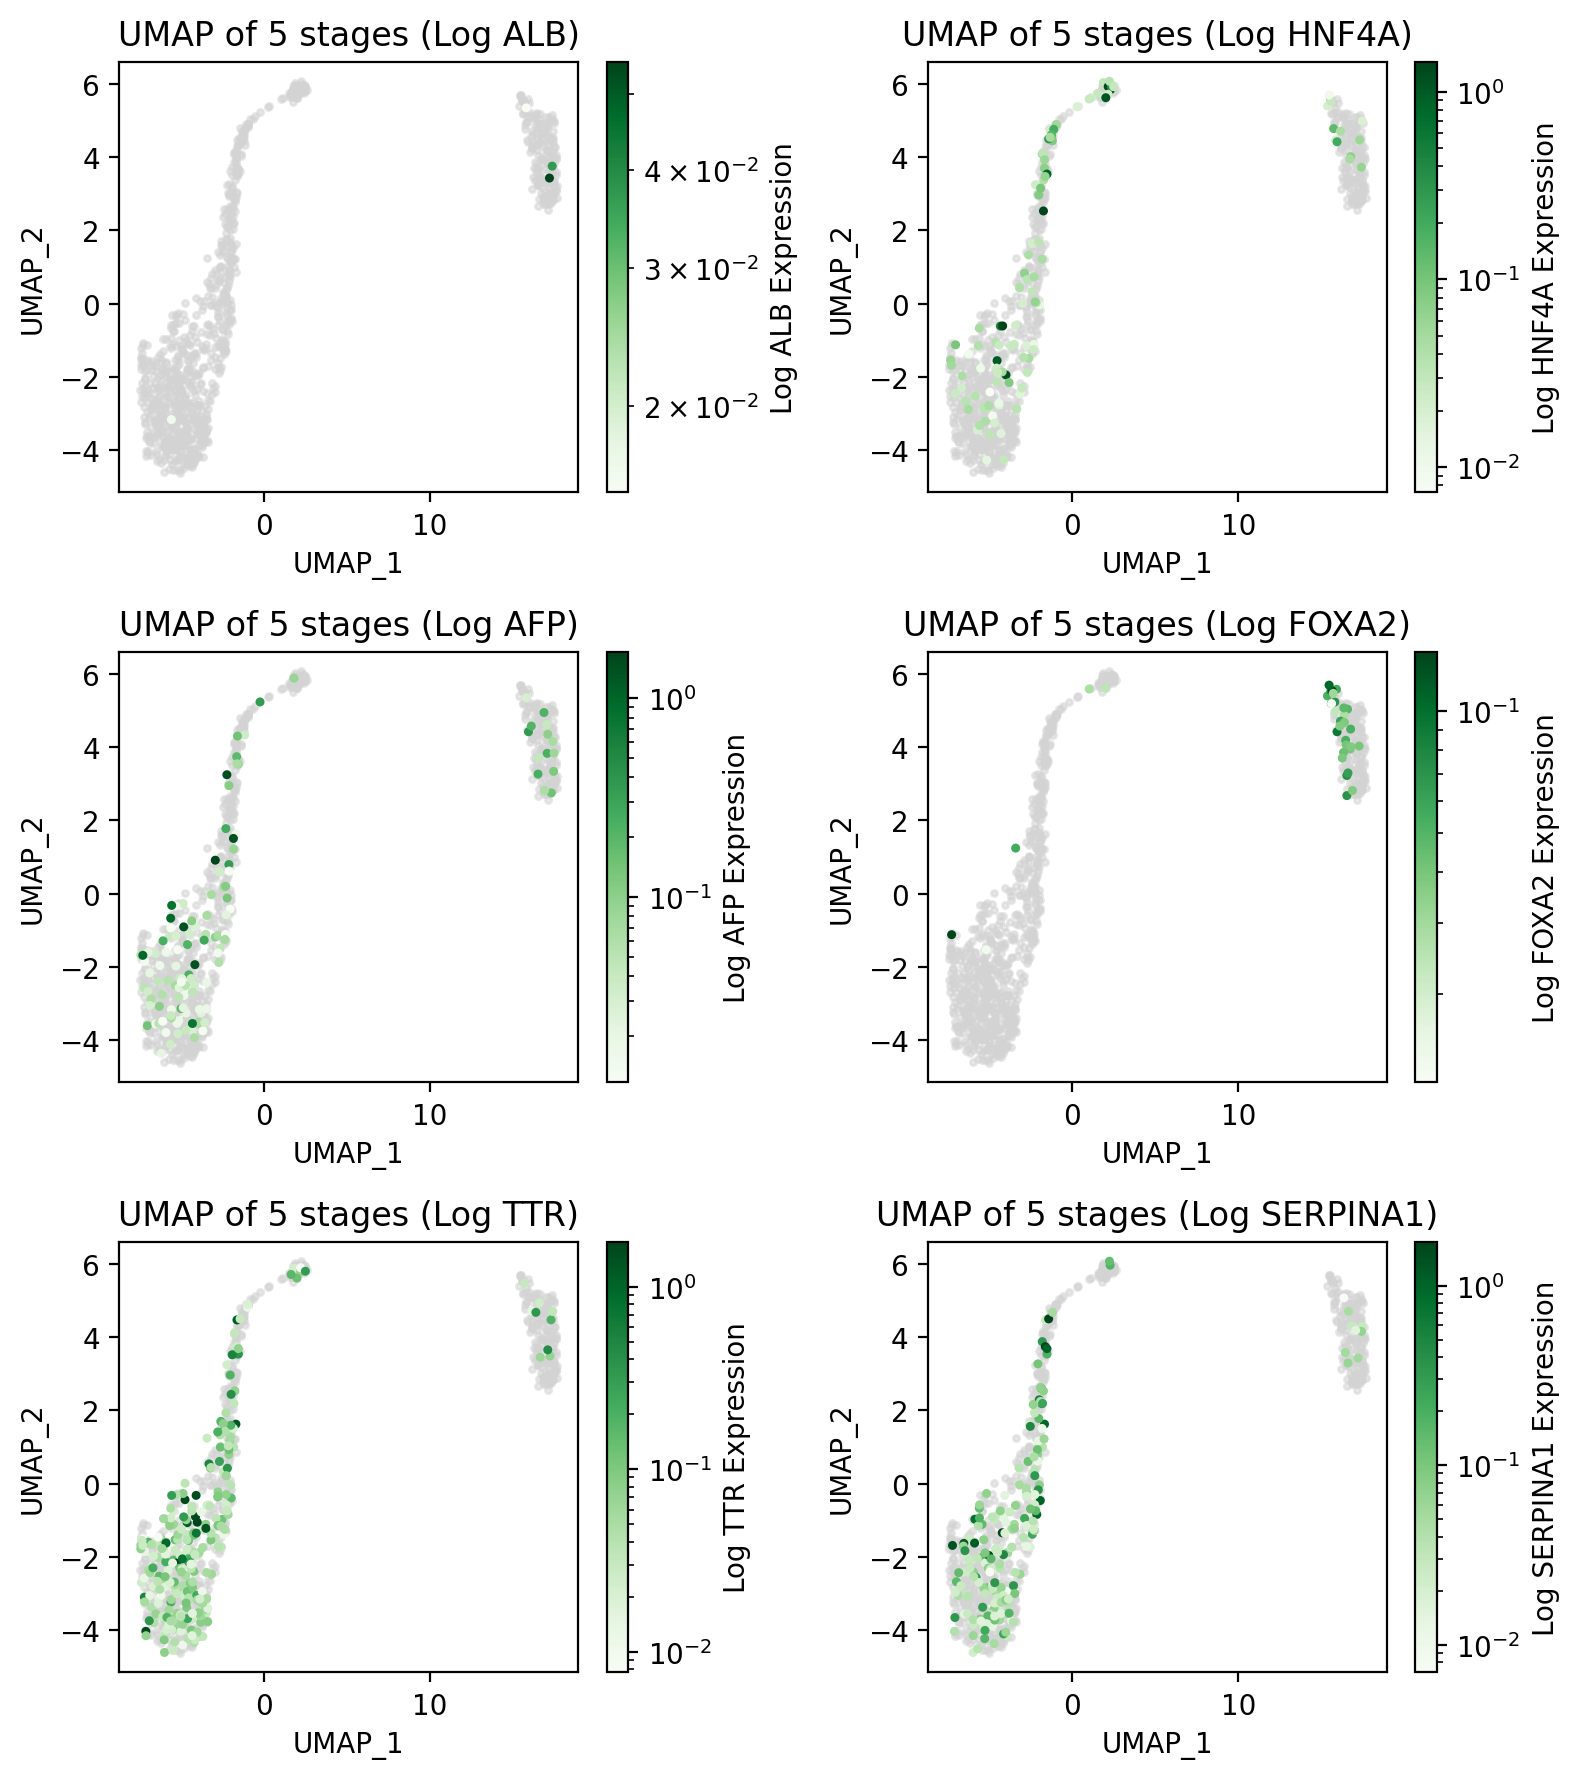

In [13]:
# Hep marker genes 
data = fivestages_Umap_featuregene
Hep_markergene = ['ALB', 'HNF4A', 'AFP', 'FOXA2','TTR','SERPINA1']

# Apply log transformation to gene expression values
data_logged = data.copy()
for gene in Hep_markergene:
    data_logged[gene] = np.log1p(data[gene])  # log1p to avoid log(0) issues

# Define subplot grid
n_rows = len(Hep_markergene) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(8, n_rows * 3), dpi=200)

# Flatten axes array in case of 2D grid
axes = axes.flatten()

# Loop over genes and plot log-transformed values
for i, gene in enumerate(Hep_markergene):
    ax = axes[i]
    
    # Log transformation for color scaling
    log_expression = np.log1p(data[gene])

    # Define blue gradient colormap
    cmap = cm.get_cmap("Greens")  

    # Normalize color scaling (log scale)
    norm = mcolors.LogNorm(vmin=log_expression[log_expression > 0].min(), vmax=log_expression.max())

    # Plot zero-expression points in grey
    ax.scatter(data["UMAP_1"][log_expression == 0], 
               data["UMAP_2"][log_expression == 0], 
               color="lightgrey", s=5, alpha=0.5)

    # Plot nonzero expression points with gradient
    scatter = ax.scatter(
        data["UMAP_1"][log_expression > 0], 
        data["UMAP_2"][log_expression > 0], 
        c=log_expression[log_expression > 0], cmap=cmap, norm=norm,
        s=5  # Small dot size
    )

    # Set subplot title and labels
    axes[i].set_title(f"UMAP of 5 stages (Log {gene})")
    axes[i].set_xlabel("UMAP_1")
    axes[i].set_ylabel("UMAP_2")

    # Add colorbar
    cbar = fig.colorbar(scatter, ax=axes[i])
    cbar.set_label(f"Log {gene} Expression")

# Adjust layout and save the plot
plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umaps_Hepmakergenes.pdf", format="pdf", bbox_inches="tight")

# Display plot
plt.show()

/tmp/ipykernel_1917021/532871823.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("Greens")


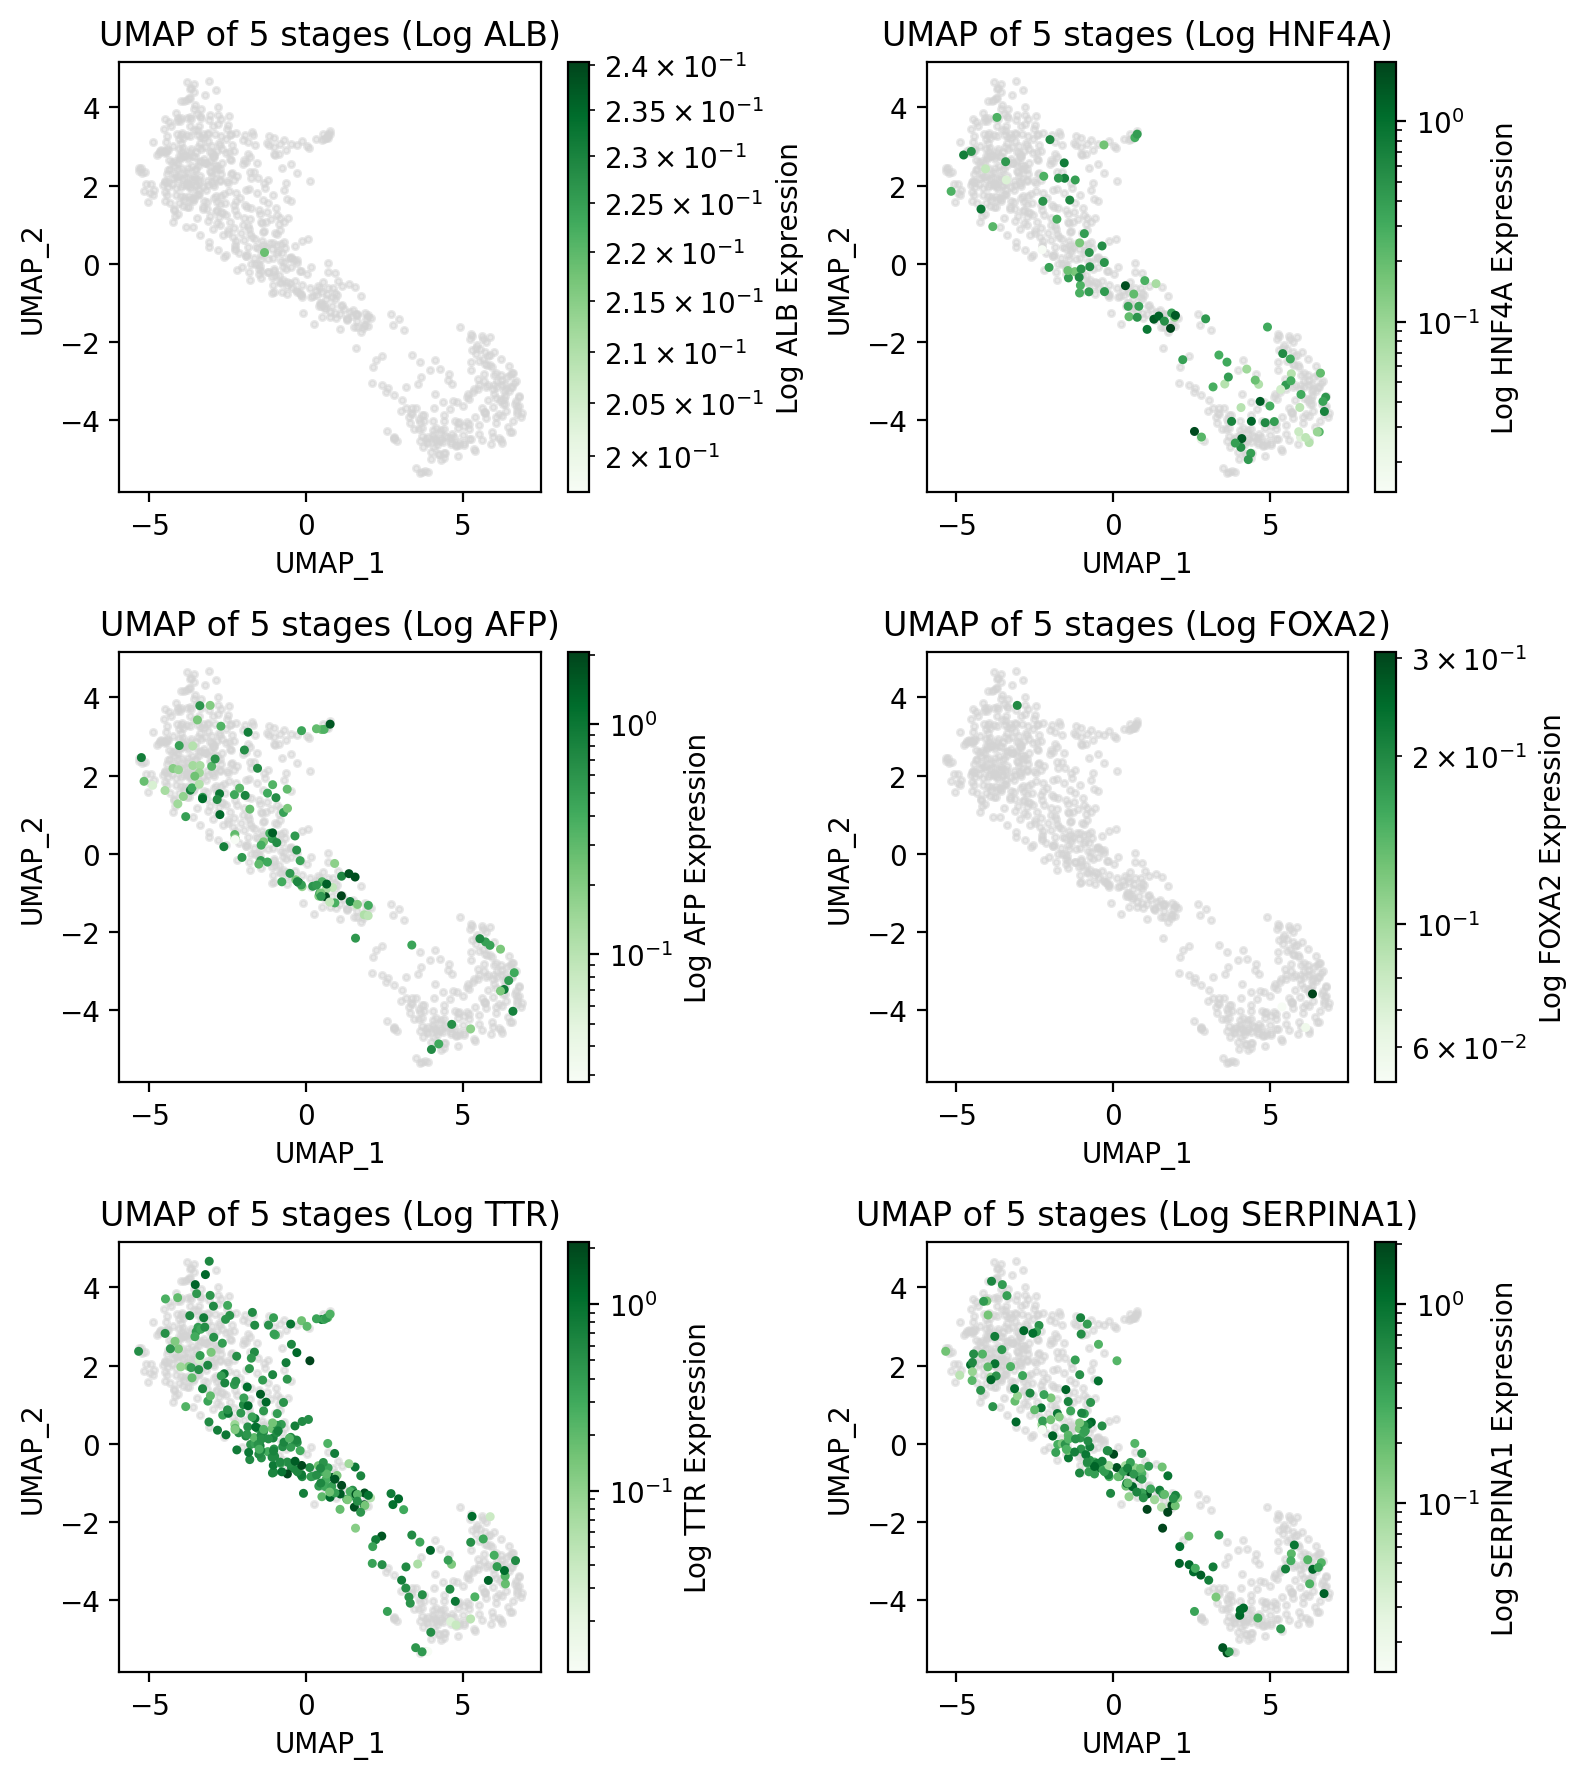

In [14]:
data = fourstages_Umap_featuregene 
Hep_markergene = ['ALB', 'HNF4A', 'AFP', 'FOXA2','TTR','SERPINA1']

# Apply log transformation to gene expression values
data_logged = data.copy()
for gene in Hep_markergene:
    data_logged[gene] = np.log1p(data[gene])  # log1p to avoid log(0) issues

# Define subplot grid
n_rows = len(Hep_markergene) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(8, n_rows * 3), dpi=200)

# Flatten axes array in case of 2D grid
axes = axes.flatten()

# Loop over genes and plot log-transformed values
for i, gene in enumerate(Hep_markergene):
    ax = axes[i]
    
    # Log transformation for color scaling
    log_expression = np.log1p(data[gene])

    # Define blue gradient colormap
    cmap = cm.get_cmap("Greens")  

    # Normalize color scaling (log scale)
    norm = mcolors.LogNorm(vmin=log_expression[log_expression > 0].min(), vmax=log_expression.max())

    # Plot zero-expression points in grey
    ax.scatter(data["UMAP_1"][log_expression == 0], 
               data["UMAP_2"][log_expression == 0], 
               color="lightgrey", s=5, alpha=0.5)

    # Plot nonzero expression points with gradient
    scatter = ax.scatter(
        data["UMAP_1"][log_expression > 0], 
        data["UMAP_2"][log_expression > 0], 
        c=log_expression[log_expression > 0], cmap=cmap, norm=norm,
        s=5  # Small dot size
    )

    # Set subplot title and labels
    axes[i].set_title(f"UMAP of 5 stages (Log {gene})")
    axes[i].set_xlabel("UMAP_1")
    axes[i].set_ylabel("UMAP_2")

    # Add colorbar
    cbar = fig.colorbar(scatter, ax=axes[i])
    cbar.set_label(f"Log {gene} Expression")

# Adjust layout and save the plot
plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/scRNA-seq_Umaps_four_stages_Hepmakergenes.pdf", format="pdf", bbox_inches="tight")

# Display plot
plt.show()